<a href="https://colab.research.google.com/github/gnichimariem1-cell/predivol/blob/main/PrediVol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PrédiVol : collecte, exploration et préparation des données


## 0. Paramètres

In [1]:
# ===== PARAMÈTRES (modifiez seulement ici) =====
DOSSIER_DONNEES = None    # None = téléchargement automatique depuis Kaggle
                          # sinon, chemin du dossier qui contient les CSV (ex. "/content/drive/MyDrive/predivol")
FRACTION = 1.0            # 1.0 = tous les vols ; mettez 0.3 si Colab manque de mémoire (30 % des vols au hasard)
GRAINE = 42

In [2]:
import os, re, glob, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
BLEU, ORANGE, ROUGE = "#3b5ba5", "#e07b24", "#c0392b"

def sauver(nom):
    plt.tight_layout()
    plt.savefig(f"figures/{nom}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Téléchargement des données

Le téléchargement automatique utilise `kagglehub`. S'il échoue (par exemple parce que Kaggle demande une connexion) :
1. téléchargez le jeu sur [la page Kaggle](https://www.kaggle.com/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft) (bouton *Download*) ;
2. décompressez-le dans votre Google Drive ;
3. montez le Drive dans Colab (icône de dossier à gauche, puis *Monter Drive*) et indiquez le dossier dans `DOSSIER_DONNEES`.

In [3]:
if DOSSIER_DONNEES is None:
    try:
        import kagglehub
    except ImportError:
        %pip -q install kagglehub
        import kagglehub
    DOSSIER_DONNEES = kagglehub.dataset_download("bordanova/2023-us-civil-flights-delay-meteo-and-aircraft")

print("Dossier :", DOSSIER_DONNEES)
fichiers = sorted(glob.glob(os.path.join(DOSSIER_DONNEES, "**", "*.csv"), recursive=True))
for f in fichiers:
    print(f"{os.path.getsize(f)/1e6:9.1f} Mo   {os.path.basename(f)}")

def choisir(motcle):
    trouves = [f for f in fichiers if motcle in os.path.basename(f).lower()]
    return trouves[0] if trouves else None

F_VOLS = choisir("us_flights_2023") or choisir("flights")
F_METEO = choisir("weather")
F_ANNULES = choisir("cancel")
print("\nVols    :", F_VOLS)
print("Météo   :", F_METEO)
print("Annulés :", F_ANNULES)
assert F_VOLS, "Fichier des vols introuvable : vérifiez DOSSIER_DONNEES."

100%|██████████| 127M/127M [00:01<00:00, 72.9MB/s]

Extracting files...


Dossier : /root/.cache/kagglehub/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft/versions/9
     18.7 Mo   Cancelled_Diverted_2023.csv
   1151.9 Mo   US_flights_2023.csv
      0.0 Mo   airports_geolocation.csv
     90.1 Mo   maj us flight - january 2024.csv
      7.4 Mo   weather_meteo_by_airport.csv

Vols    : /root/.cache/kagglehub/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft/versions/9/US_flights_2023.csv
Météo   : /root/.cache/kagglehub/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft/versions/9/weather_meteo_by_airport.csv
Annulés : /root/.cache/kagglehub/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft/versions/9/Cancelled_Diverted_2023.csv


In [4]:
rng = np.random.default_rng(GRAINE)
lignes_a_sauter = (lambda i: i > 0 and rng.random() > FRACTION) if FRACTION < 1 else None
vols = pd.read_csv(F_VOLS, low_memory=False, skiprows=lignes_a_sauter)

# Les colonnes texte répétitives deviennent des catégories (beaucoup moins de mémoire)
for c in vols.select_dtypes("object").columns:
    if vols[c].nunique() < 0.5 * len(vols):
        vols[c] = vols[c].astype("category")

print(f"{len(vols):,} vols × {vols.shape[1]} colonnes – mémoire : {vols.memory_usage(deep=True).sum()/1e9:.2f} Go")
print("\nColonnes :", list(vols.columns))
vols.head()

6,743,404 vols × 24 colonnes – mémoire : 0.72 Go

Colonnes : ['FlightDate', 'Day_Of_Week', 'Airline', 'Tail_Number', 'Dep_Airport', 'Dep_CityName', 'DepTime_label', 'Dep_Delay', 'Dep_Delay_Tag', 'Dep_Delay_Type', 'Arr_Airport', 'Arr_CityName', 'Arr_Delay', 'Arr_Delay_Type', 'Flight_Duration', 'Distance_type', 'Delay_Carrier', 'Delay_Weather', 'Delay_NAS', 'Delay_Security', 'Delay_LastAircraft', 'Manufacturer', 'Model', 'Aicraft_age']


,FlightDate,Day_Of_Week,Airline,Tail_Number,Dep_Airport,Dep_CityName,DepTime_label,Dep_Delay,Dep_Delay_Tag,Dep_Delay_Type,Arr_Airport,Arr_CityName,Arr_Delay,Arr_Delay_Type,Flight_Duration,Distance_type,Delay_Carrier,Delay_Weather,Delay_NAS,Delay_Security,Delay_LastAircraft,Manufacturer,Model,Aicraft_age
0,2023-01-02,1,Endeavor Air,N605LR,BDL,"Hartford, CT",Morning,-3,0,Low <5min,LGA,"New York, NY",-12,Low <5min,56,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,16
1,2023-01-03,2,Endeavor Air,N605LR,BDL,"Hartford, CT",Morning,-5,0,Low <5min,LGA,"New York, NY",-8,Low <5min,62,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,16
2,2023-01-04,3,Endeavor Air,N331PQ,BDL,"Hartford, CT",Morning,-5,0,Low <5min,LGA,"New York, NY",-21,Low <5min,49,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,10
3,2023-01-05,4,Endeavor Air,N906XJ,BDL,"Hartford, CT",Morning,-6,0,Low <5min,LGA,"New York, NY",-17,Low <5min,54,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,17
4,2023-01-06,5,Endeavor Air,N337PQ,BDL,"Hartford, CT",Morning,-1,0,Low <5min,LGA,"New York, NY",-16,Low <5min,50,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,10


## 2. Repérage automatique des colonnes

Les noms exacts des colonnes ne sont pas garantis : cette cellule les retrouve. Si une ligne affiche `None` alors que la colonne existe, écrivez son nom à la main, par exemple `C["avion"] = "Tail_Number"`.

In [5]:
def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def trouver(df, *candidats):
    index = {norm(c): c for c in df.columns}
    for cand in candidats:
        if norm(cand) in index:
            return index[norm(cand)]
    return None

C = dict(
    date=trouver(vols, "FlightDate", "FL_DATE", "Flight_Date", "Date"),
    compagnie=trouver(vols, "Airline", "Carrier", "OP_UNIQUE_CARRIER", "Reporting_Airline"),
    avion=trouver(vols, "Tail_Number", "TailNum", "Tail_Num"),
    dep=trouver(vols, "Dep_Airport", "Origin", "ORIGIN_AIRPORT", "Origin_Airport"),
    arr=trouver(vols, "Arr_Airport", "Dest", "DESTINATION_AIRPORT", "Dest_Airport"),
    heure=trouver(vols, "CRS_Dep_Time", "CRSDepTime", "Scheduled_Departure", "DepTime_label", "Dep_Time_Blk", "DEP_TIME_BLK"),
    cible=trouver(vols, "Arr_Delay", "ARRIVAL_DELAY", "ArrDelay"),
    dep_delay=trouver(vols, "Dep_Delay", "DEPARTURE_DELAY", "DepDelay"),
    distance=trouver(vols, "Distance", "Distance_type", "DISTANCE"),
    duree=trouver(vols, "Flight_Duration", "CRS_Elapsed_Time", "Scheduled_Time"),
    age=trouver(vols, "Aicraft_age", "Aircraft_age", "Aircraft_Age"),
    constructeur=trouver(vols, "Manufacturer"),
    modele=trouver(vols, "Model"),
)
for k, v in C.items():
    print(f"{k:13s} -> {v}")
assert C["cible"], "Colonne du retard à l'arrivée introuvable : écrivez son nom, ex. C['cible'] = 'Arr_Delay'"
assert C["date"], "Colonne de date introuvable : écrivez son nom, ex. C['date'] = 'FlightDate'"

# Colonnes connues seulement APRÈS le départ = fuite de données (exclues des modèles)
FUITE = [c for c in vols.columns if c != C["cible"] and re.search(
    r"dep_?delay|^delay_|_delay$|delay_?(type|tag|group)|del15|taxi|wheels|air_?time|actual|^elapsed", c, re.I)]
print("\nFuite de données (exclues des modèles) :", FUITE)
print("À vérifier : la durée", C["duree"], "et l'heure", C["heure"],
      "sont-elles PRÉVUES (utilisables) ou RÉELLES (fuite) ? Regardez la documentation Kaggle.")

date          -> FlightDate
compagnie     -> Airline
avion         -> Tail_Number
dep           -> Dep_Airport
arr           -> Arr_Airport
heure         -> DepTime_label
cible         -> Arr_Delay
dep_delay     -> Dep_Delay
distance      -> Distance_type
duree         -> Flight_Duration
age           -> Aicraft_age
constructeur  -> Manufacturer
modele        -> Model

Fuite de données (exclues des modèles) : ['Dep_Delay', 'Dep_Delay_Tag', 'Dep_Delay_Type', 'Arr_Delay_Type', 'Delay_Carrier', 'Delay_Weather', 'Delay_NAS', 'Delay_Security', 'Delay_LastAircraft']
À vérifier : la durée Flight_Duration et l'heure DepTime_label sont-elles PRÉVUES (utilisables) ou RÉELLES (fuite) ? Regardez la documentation Kaggle.


## 3. Aperçu : types, valeurs manquantes, doublons

In [6]:
apercu = pd.DataFrame({
    "type": vols.dtypes.astype(str),
    "manquantes_%": (vols.isna().mean() * 100).round(2),
    "valeurs_distinctes": vols.nunique(),
    "exemple": vols.iloc[0],
})
apercu["role"] = np.where(apercu.index == C["cible"], "CIBLE", np.where(apercu.index.isin(FUITE), "fuite (exclue)", ""))
display(apercu)

nb_doublons = int(vols.duplicated().sum())
vols["_date"] = pd.to_datetime(vols[C["date"]], errors="coerce").dt.normalize()
print("Nombre de vols", ":", f"{len(vols):,}")
print("Nombre de colonnes", ":", vols.shape[1] - 1)
print("Période", ":", f"{vols['_date'].min():%Y-%m-%d} au {vols['_date'].max():%Y-%m-%d}")
print("Colonnes avec valeurs manquantes", ":", ", ".join(f"{i} ({v} %)" for i, v in apercu["manquantes_%"].items() if v > 0) or "aucune")
print("Doublons :", nb_doublons)

,type,manquantes_%,valeurs_distinctes,exemple,role
FlightDate,category,0.0,365,2023-01-02,
Day_Of_Week,int64,0.0,7,1,
Airline,category,0.0,15,Endeavor Air,
Tail_Number,category,0.0,5963,N605LR,
Dep_Airport,category,0.0,350,BDL,
Dep_CityName,category,0.0,344,"Hartford, CT",
DepTime_label,category,0.0,4,Morning,
Dep_Delay,int64,0.0,1854,-3,fuite (exclue)
Dep_Delay_Tag,int64,0.0,2,0,fuite (exclue)
Dep_Delay_Type,category,0.0,3,Low <5min,fuite (exclue)


Nombre de vols : 6,743,404
Nombre de colonnes : 24
Période : 2023-01-01 au 2023-12-31
Colonnes avec valeurs manquantes : aucune
Doublons : 31


## 4. La cible : retard à l'arrivée (minutes)

Valeur négative = arrivée en avance. On regarde la forme de la distribution et les valeurs extrêmes.

,retard à l'arrivée (min)
count,6743404.0
mean,6.6
std,57.1
min,-119.0
5%,-27.0
25%,-15.0
50%,-6.0
75%,9.0
90%,41.0
95%,78.0


Retard moyen (min) : 6.6
Retard médian (min) : -6.0
% vols en avance : 61.5
% vols avec 15 min de retard ou plus : 20.6
% vols avec 60 min de retard ou plus : 6.9
Retard maximal (min) : 4405
Asymétrie (skewness) : 10.93


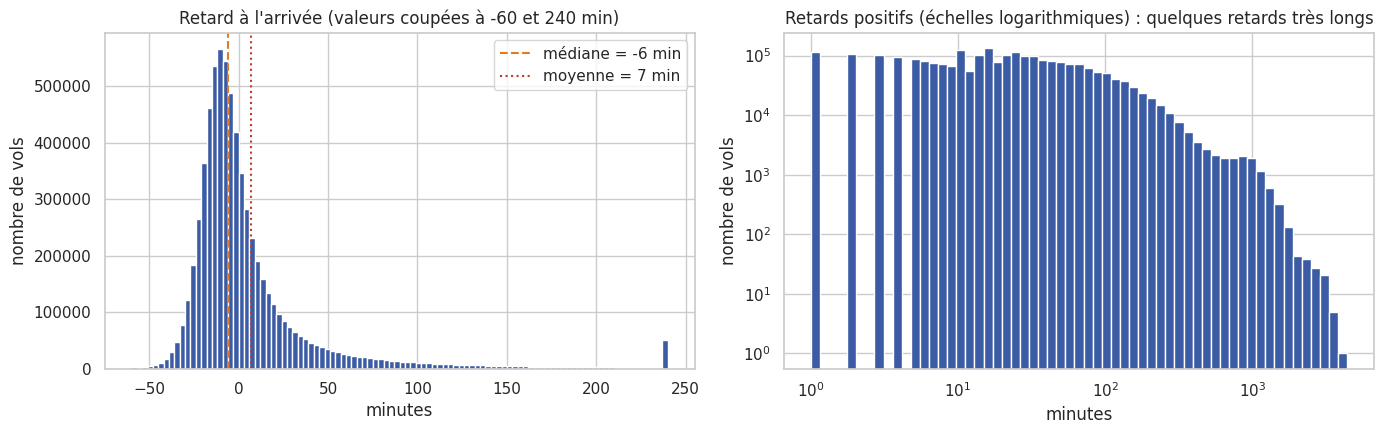

In [7]:
y = vols[C["cible"]].dropna()
display(y.describe(percentiles=[.05, .25, .5, .75, .9, .95, .99]).round(1).to_frame("retard à l'arrivée (min)"))

print("Retard moyen (min)", ":", round(y.mean(), 1))
print("Retard médian (min)", ":", round(y.median(), 1))
print("% vols en avance", ":", round((y < 0).mean() * 100, 1))
print("% vols avec 15 min de retard ou plus", ":", round((y >= 15).mean() * 100, 1))
print("% vols avec 60 min de retard ou plus", ":", round((y >= 60).mean() * 100, 1))
print("Retard maximal (min)", ":", int(y.max()))
print("Asymétrie (skewness)", ":", round(y.skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(y.clip(-60, 240), bins=100, color=BLEU)
ax[0].axvline(y.median(), color=ORANGE, ls="--", label=f"médiane = {y.median():.0f} min")
ax[0].axvline(y.mean(), color=ROUGE, ls=":", label=f"moyenne = {y.mean():.0f} min")
ax[0].set(title="Retard à l'arrivée (valeurs coupées à -60 et 240 min)", xlabel="minutes", ylabel="nombre de vols")
ax[0].legend()
pos = y[y > 0]
ax[1].hist(pos, bins=np.logspace(0, np.log10(pos.max() + 1), 60), color=BLEU)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set(title="Retards positifs (échelles logarithmiques) : quelques retards très longs", xlabel="minutes", ylabel="nombre de vols")
sauver("01_distribution_retard")

## 5. Variables dérivées

Toutes ces variables sont **connues avant le départ** (pas de fuite de données) :
- le mois, le jour de la semaine et le moment de la journée ;
- l'**effet domino** : le nombre de vols du même avion ce jour-là ;
- le **trafic prévu** : le nombre de vols programmés ce jour-là à l'aéroport de départ et à l'aéroport d'arrivée (mesure de la congestion) ;
- la **proximité d'un jour férié** américain (Thanksgiving, Noël, 4 juillet…).

In [8]:
vols["mois"] = vols["_date"].dt.month
vols["jour_semaine"] = vols["_date"].dt.dayofweek + 1          # 1 = lundi … 7 = dimanche

h = C["heure"]
if h is not None and pd.api.types.is_numeric_dtype(vols[h]):
    vols["heure_dep"] = (vols[h] // 100).clip(0, 23)            # format HHMM -> heure
    vols["tranche"] = pd.cut(vols["heure_dep"], [-1, 5, 11, 17, 21, 23],
                             labels=["nuit", "matin", "après-midi", "soir", "nuit tardive"])
elif h is not None:
    vols["tranche"] = vols[h].astype("category")                 # étiquette déjà fournie (ex. Morning)

# Effet domino : nombre de vols du même avion le même jour (connu dans le planning avant le départ)
if C["avion"]:
    vols["vols_jour_avion"] = vols.groupby([C["avion"], "_date"], observed=True)[C["cible"]].transform("size").astype("float32")
    if "heure_dep" in vols:
        vols["rang_vol_jour"] = vols.groupby([C["avion"], "_date"], observed=True)["heure_dep"].rank(method="first").astype("float32")
    print(vols["vols_jour_avion"].describe().round(2))
else:
    print("Pas de numéro d'avion : l'effet domino ne peut pas être calculé.")

count    6743404.00
mean           4.80
std            1.63
min            1.00
25%            4.00
50%            5.00
75%            6.00
max           13.00
Name: vols_jour_avion, dtype: float64


In [9]:
# Trafic prévu : vols programmés le même jour au même aéroport (les vols annulés font aussi partie du planning)
planning = pd.DataFrame({"dep": vols[C["dep"]].astype(str), "arr": vols[C["arr"]].astype(str), "_date": vols["_date"]})
if F_ANNULES:
    try:
        ann = pd.read_csv(F_ANNULES, low_memory=False)
        a_dep, a_arr, a_date = trouver(ann, C["dep"]), trouver(ann, C["arr"]), trouver(ann, C["date"])
        if a_dep and a_arr and a_date:
            ann = pd.DataFrame({"dep": ann[a_dep].astype(str), "arr": ann[a_arr].astype(str),
                                "_date": pd.to_datetime(ann[a_date], errors="coerce").dt.normalize()})
            if FRACTION < 1:
                ann = ann.sample(frac=FRACTION, random_state=GRAINE)
            planning = pd.concat([planning, ann], ignore_index=True)
            print(f"Vols annulés ou déroutés ajoutés au planning : {len(ann):,}")
    except Exception as e:
        print("Fichier des annulés non utilisé :", e)

for cote in ["dep", "arr"]:
    par_jour = planning.groupby([cote, "_date"]).size()
    cle = pd.MultiIndex.from_arrays([vols[C[cote]].astype(str), vols["_date"]])
    vols[f"trafic_{cote}_jour"] = (par_jour.reindex(cle).to_numpy(dtype="float64") / FRACTION).astype("float32")
print(vols[["trafic_dep_jour", "trafic_arr_jour"]].describe().round(0))

# Jours fériés américains : nombre de jours jusqu'au jour férié le plus proche (plafonné à 15)
FERIES_2023 = ["2023-01-01", "2023-01-02", "2023-01-16", "2023-02-20", "2023-05-29", "2023-06-19", "2023-07-04",
               "2023-09-04", "2023-10-09", "2023-11-10", "2023-11-11", "2023-11-23", "2023-12-25"]
annees = sorted(int(a) for a in vols["_date"].dt.year.dropna().unique())
try:
    import holidays
    feries = pd.to_datetime([d for a in range(annees[0] - 1, annees[-1] + 2) for d in holidays.US(years=a).keys()])
    print("Jours fériés : bibliothèque holidays")
except Exception:
    feries = pd.to_datetime(FERIES_2023)
    print("Jours fériés : liste 2023 intégrée")
feries = np.sort(feries.values.astype("datetime64[D]"))
jours = vols["_date"].values.astype("datetime64[D]")
pos = np.searchsorted(feries, jours)
avant = feries[np.clip(pos - 1, 0, len(feries) - 1)]
apres = feries[np.clip(pos, 0, len(feries) - 1)]
ecart = np.minimum(np.abs((jours - avant).astype("int64")), np.abs((apres - jours).astype("int64"))).astype("float32")
ecart[vols["_date"].isna().to_numpy()] = np.nan
vols["jours_ferie"] = np.clip(ecart, 0, 15)
print(f"Vols à 3 jours ou moins d'un jour férié : {(vols['jours_ferie'] <= 3).mean() * 100:.1f} %")

Vols annulés ou déroutés ajoutés au planning : 104,488
       trafic_dep_jour  trafic_arr_jour
count        6743404.0        6743404.0
mean             350.0            350.0
std              266.0            266.0
min                1.0              1.0
25%              121.0            121.0
50%              305.0            305.0
75%              512.0            512.0
max             1030.0           1030.0
Jours fériés : bibliothèque holidays
Vols à 3 jours ou moins d'un jour férié : 21.3 %


## 6. Quand et où les retards sont-ils les plus forts ?

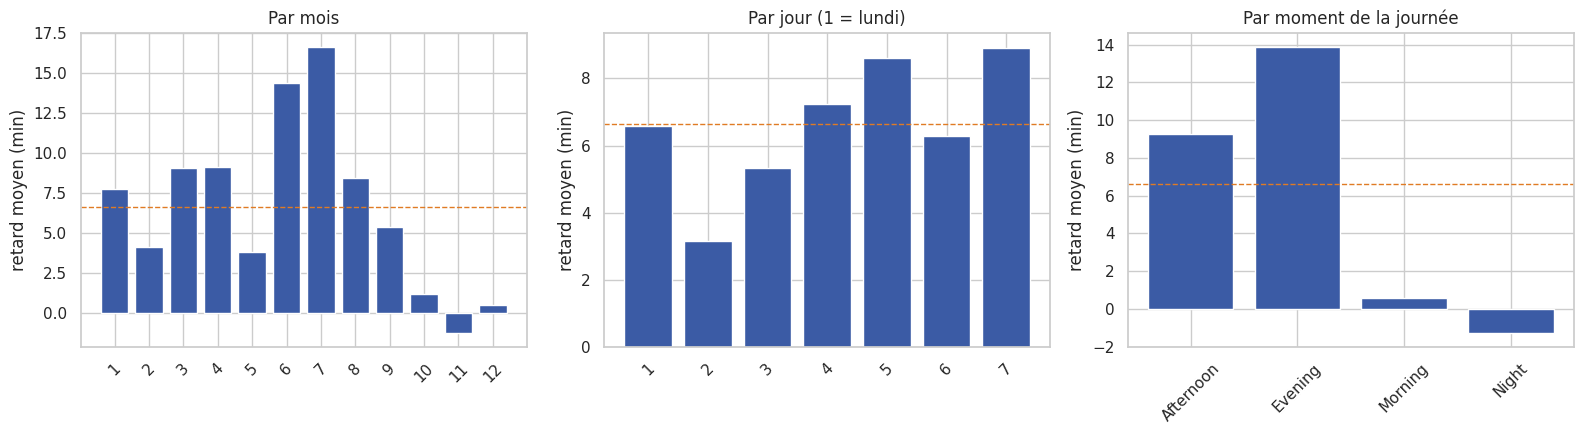

Mois le plus en retard : 7 (16.6 min en moyenne)
Mois le moins en retard : 11 (-1.3 min en moyenne)


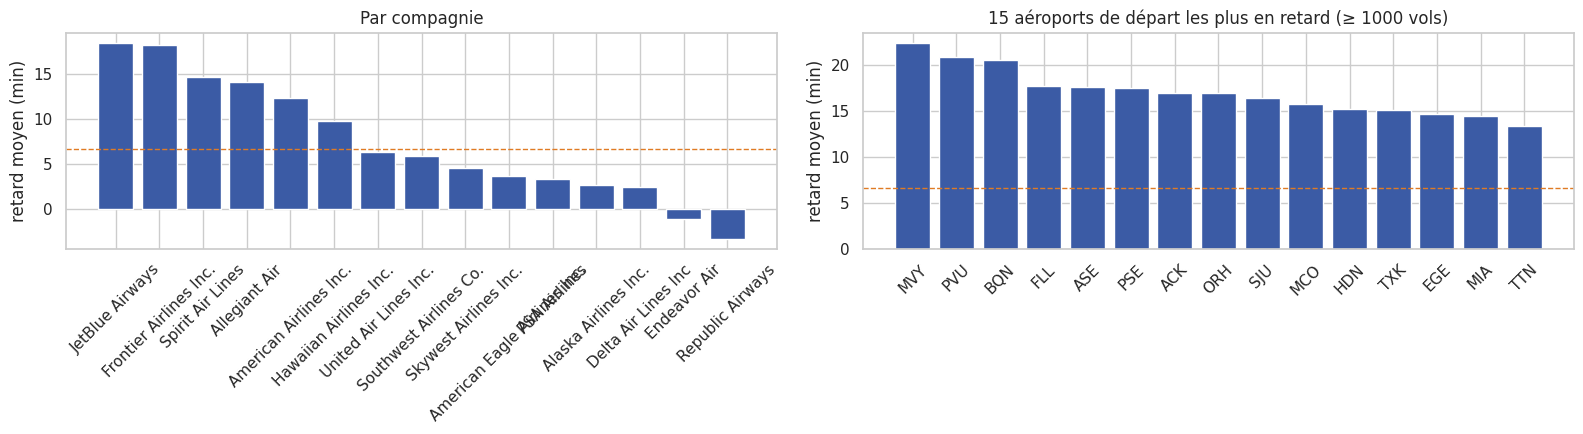

Compagnie la plus en retard : JetBlue Airways (18.5 min)
Aéroport de départ le plus en retard : MVY (22.4 min)


In [10]:
MIN_VOLS = 1000 if len(vols) > 1_000_000 else 100

def profil(col, titre, ax, ordre=None, top=None, min_vols=0):
    g = vols.groupby(col, observed=True)[C["cible"]].agg(["mean", "count"])
    g = g[g["count"] >= min_vols]
    if top:
        g = g.sort_values("mean", ascending=False).head(top)
    elif ordre is not None:
        g = g.reindex([o for o in ordre if o in g.index])
    ax.bar(g.index.astype(str), g["mean"], color=BLEU)
    ax.axhline(vols[C["cible"]].mean(), color=ORANGE, ls="--", lw=1)
    ax.set(title=titre, ylabel="retard moyen (min)")
    ax.tick_params(axis="x", rotation=45)
    return g

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
g_mois = profil("mois", "Par mois", ax[0], ordre=range(1, 13))
profil("jour_semaine", "Par jour (1 = lundi)", ax[1], ordre=range(1, 8))
if "tranche" in vols:
    g_tr = profil("tranche", "Par moment de la journée", ax[2])
sauver("02_retard_par_periode")
print("Mois le plus en retard", ":", f"{int(g_mois['mean'].idxmax())} ({g_mois['mean'].max():.1f} min en moyenne)")
print("Mois le moins en retard", ":", f"{int(g_mois['mean'].idxmin())} ({g_mois['mean'].min():.1f} min en moyenne)")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
g_cie = profil(C["compagnie"], "Par compagnie", ax[0], top=30)
g_aer = profil(C["dep"], f"15 aéroports de départ les plus en retard (≥ {MIN_VOLS} vols)", ax[1], top=15, min_vols=MIN_VOLS)
sauver("03_retard_par_compagnie_aeroport")
print("Compagnie la plus en retard", ":", f"{g_cie['mean'].idxmax()} ({g_cie['mean'].max():.1f} min)")
print("Aéroport de départ le plus en retard", ":", f"{g_aer['mean'].idxmax()} ({g_aer['mean'].max():.1f} min)")

La moyenne est tirée vers le haut par quelques retards très longs. On regarde donc aussi la **part des vols en retard de 15 minutes ou plus**, la définition officielle d'un vol « en retard » aux États-Unis.

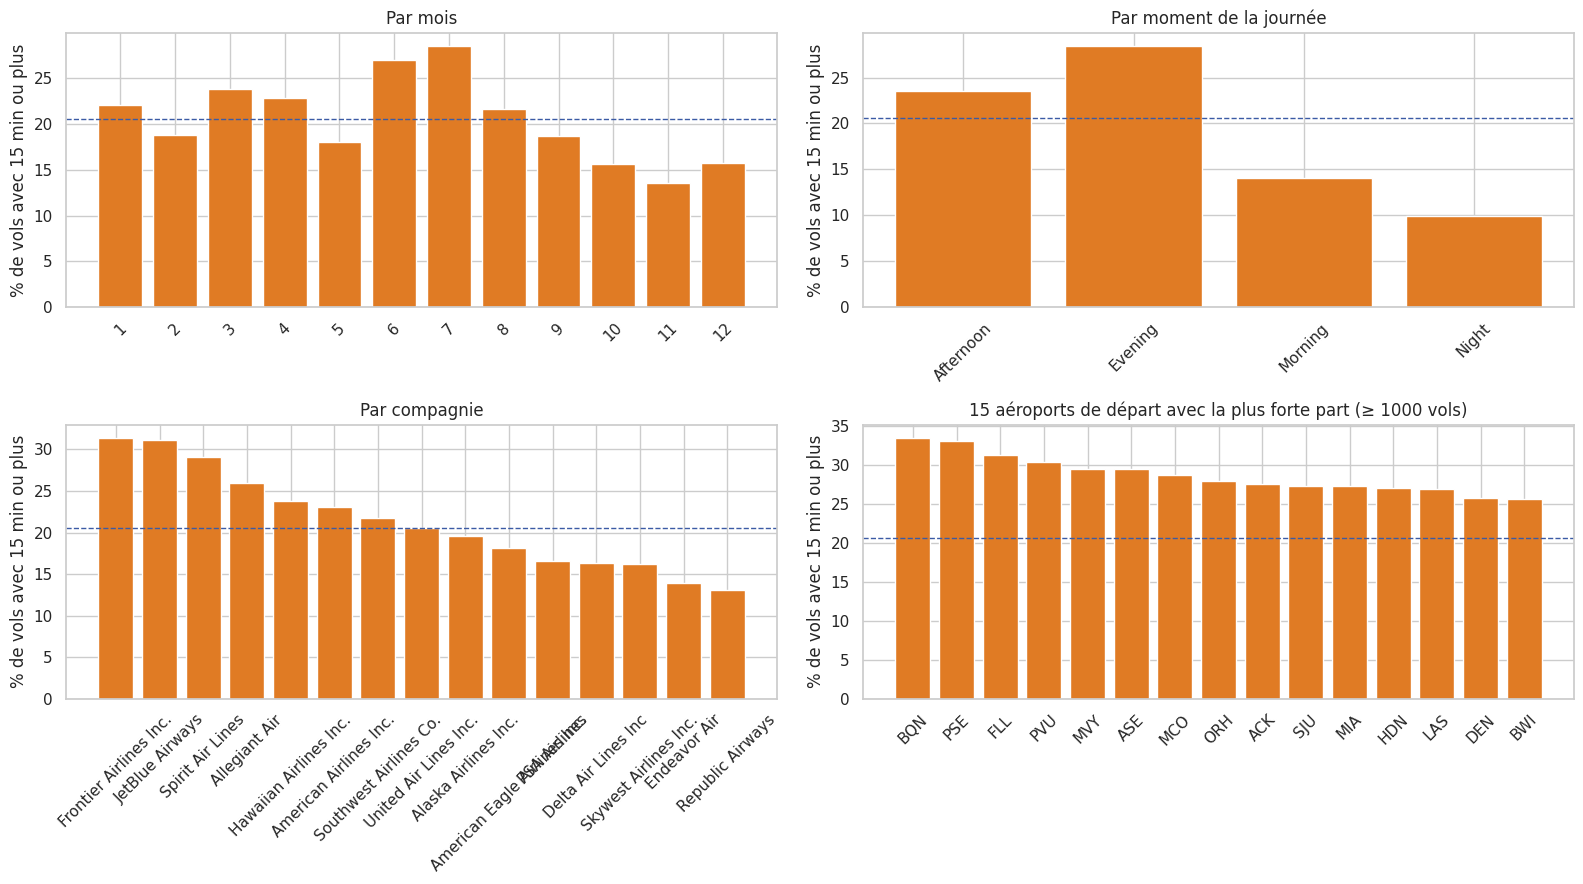

Mois avec la plus forte part de vols en retard (≥ 15 min) : 7 (28.6 %)
Compagnie avec la plus forte part de vols en retard : Frontier Airlines Inc. (31.4 %)
Aéroport avec la plus forte part de vols en retard : BQN (33.5 %)


In [11]:
TAUX_GLOBAL = (vols[C["cible"]] >= 15).mean() * 100

def part15(col, titre, ax, ordre=None, top=None, min_vols=0):
    g = vols.groupby(col, observed=True)[C["cible"]].agg(pct=lambda s: (s >= 15).mean() * 100, count="size")
    g = g[g["count"] >= min_vols]
    if top:
        g = g.sort_values("pct", ascending=False).head(top)
    elif ordre is not None:
        g = g.reindex([o for o in ordre if o in g.index])
    ax.bar(g.index.astype(str), g["pct"], color=ORANGE)
    ax.axhline(TAUX_GLOBAL, color=BLEU, ls="--", lw=1)
    ax.set(title=titre, ylabel="% de vols avec 15 min ou plus")
    ax.tick_params(axis="x", rotation=45)
    return g

fig, ax = plt.subplots(2, 2, figsize=(16, 9))
p_mois = part15("mois", "Par mois", ax[0, 0], ordre=range(1, 13))
if "tranche" in vols:
    part15("tranche", "Par moment de la journée", ax[0, 1])
p_cie = part15(C["compagnie"], "Par compagnie", ax[1, 0], top=30)
p_aer = part15(C["dep"], f"15 aéroports de départ avec la plus forte part (≥ {MIN_VOLS} vols)", ax[1, 1], top=15, min_vols=MIN_VOLS)
sauver("02b_part_vols_en_retard")
print("Mois avec la plus forte part de vols en retard (≥ 15 min)", ":", f"{int(p_mois['pct'].idxmax())} ({p_mois['pct'].max():.1f} %)")
print("Compagnie avec la plus forte part de vols en retard", ":", f"{p_cie['pct'].idxmax()} ({p_cie['pct'].max():.1f} %)")
print("Aéroport avec la plus forte part de vols en retard", ":", f"{p_aer['pct'].idxmax()} ({p_aer['pct'].max():.1f} %)")

## 7. Jointure de la météo (aéroport + date)

La météo est quotidienne. On l'ajoute pour l'aéroport de **départ** et pour celui d'**arrivée**.

> Limite à noter : c'est la météo **observée** le jour du vol. En situation réelle, on utiliserait une **prévision** météo.

In [12]:
VARS_METEO, METEO_COLS = [], []
if F_METEO:
    meteo = pd.read_csv(F_METEO, low_memory=False)
    print(meteo.shape, list(meteo.columns))
    display(meteo.head())
    m_aero = trouver(meteo, "airport_id", "airport", "iata", "iata_code", "code", "station")
    m_date = trouver(meteo, "time", "date", "day")
    print("Aéroport :", m_aero, "| Date :", m_date)
    VARS_METEO = [c for c in meteo.columns if c not in (m_aero, m_date) and pd.api.types.is_numeric_dtype(meteo[c])]
    print("Variables météo :", VARS_METEO)
    display((meteo[VARS_METEO].isna().mean() * 100).round(1).to_frame("manquantes_% (fichier météo)"))

    meteo["_date"] = pd.to_datetime(meteo[m_date], errors="coerce").dt.normalize()
    meteo[m_aero] = meteo[m_aero].astype(str)
    m = meteo[[m_aero, "_date"] + VARS_METEO].drop_duplicates([m_aero, "_date"])
    m[VARS_METEO] = m[VARS_METEO].astype("float32")
    for cote, col_vols in [("dep", C["dep"]), ("arr", C["arr"])]:
        if col_vols is None:
            continue
        mm = m.rename(columns={m_aero: "_aero", **{v: f"{v}_{cote}" for v in VARS_METEO}})
        vols["_aero"] = vols[col_vols].astype(str)
        vols = vols.merge(mm, on=["_aero", "_date"], how="left")
        METEO_COLS += [f"{v}_{cote}" for v in VARS_METEO]
    vols.drop(columns="_aero", inplace=True)
    couverture = vols[f"{VARS_METEO[0]}_dep"].notna().mean() * 100
    print("Vols avec météo de départ trouvée", ":", f"{couverture:.1f} %")
    print(f"Vols avec météo au départ : {couverture:.1f} %")
    if couverture < 50:
        print("ATTENTION : jointure faible. Les codes d'aéroport du fichier météo ne correspondent peut-être pas à ceux des vols.")
else:
    print("Pas de fichier météo trouvé.")

(132860, 10) ['time', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'pres', 'airport_id']


,time,tavg,tmin,tmax,prcp,snow,wdir,wspd,pres,airport_id
0,2023-01-01,8.1,2.2,11.7,0.0,0.0,278.0,9.7,1013.8,ABE
1,2023-01-02,5.4,0.0,11.7,0.0,0.0,353.0,3.6,1019.6,ABE
2,2023-01-03,8.4,7.2,9.4,15.2,0.0,50.0,5.0,1013.9,ABE
3,2023-01-04,11.1,6.7,17.2,0.0,0.0,302.0,4.7,1009.8,ABE
4,2023-01-05,12.7,6.7,14.4,7.9,0.0,292.0,7.2,1013.0,ABE


Aéroport : airport_id | Date : time
Variables météo : ['tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'pres']


,manquantes_% (fichier météo)
tavg,0.0
tmin,0.0
tmax,0.0
prcp,0.0
snow,0.0
wdir,0.0
wspd,0.0
pres,0.0


Vols avec météo de départ trouvée : 100.0 %
Vols avec météo au départ : 100.0 %


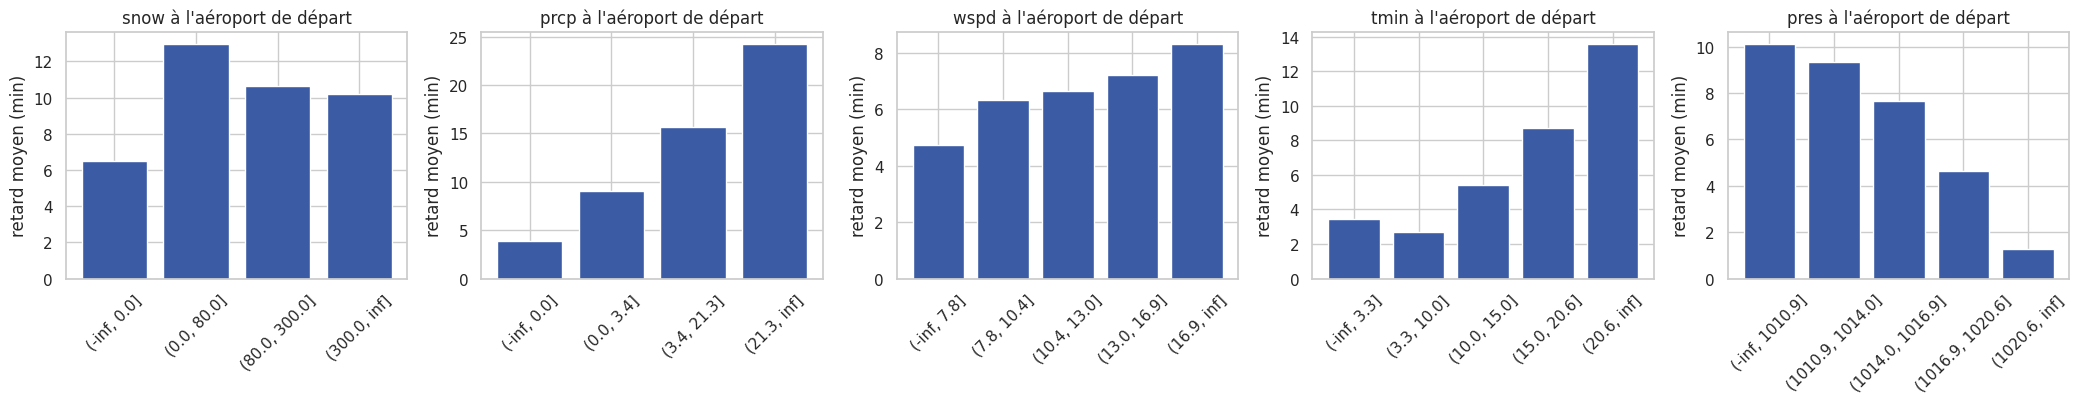

In [13]:
def classes(s):
    s = s.astype(float)
    pos = s[s > 0]
    if (s.fillna(0) == 0).mean() > 0.4 and len(pos):
        bornes = np.r_[-np.inf, 0, np.nanquantile(pos, [.5, .9]), np.inf]
    else:
        bornes = np.r_[-np.inf, np.nanquantile(s, [.2, .4, .6, .8]), np.inf]
    return pd.cut(s, np.unique(bornes))

a_tracer = [v for v in ["snow", "prcp", "wspd", "tmin", "pres"] if f"{v}_dep" in vols] or VARS_METEO[:4]
if a_tracer:
    fig, ax = plt.subplots(1, len(a_tracer), figsize=(4.2 * len(a_tracer), 4.2))
    ax = np.atleast_1d(ax)
    for a, v in zip(ax, a_tracer):
        g = vols.groupby(classes(vols[f"{v}_dep"]), observed=True)[C["cible"]].mean()
        a.bar(g.index.astype(str), g.values, color=BLEU)
        a.set(title=f"{v} à l'aéroport de départ", ylabel="retard moyen (min)")
        a.tick_params(axis="x", rotation=45)
    sauver("04_retard_selon_meteo")

## 8. Corrélations

- **Pearson** mesure une relation linéaire ; **Spearman** mesure une relation qui monte ou descend (plus robuste aux valeurs extrêmes, utile ici car la cible est très asymétrique).
- Les variables de **fuite de données** sont montrées **en rouge** pour illustrer pourquoi on les exclut : elles sont très corrélées à la cible, mais inconnues avant le départ.

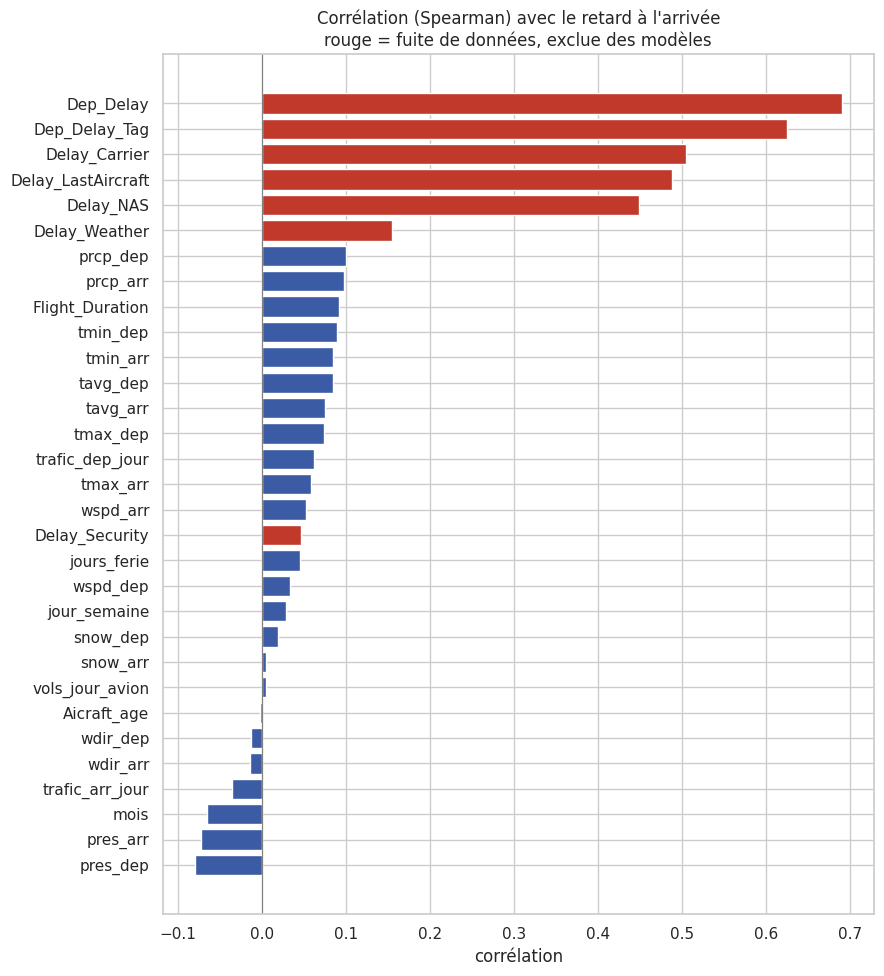

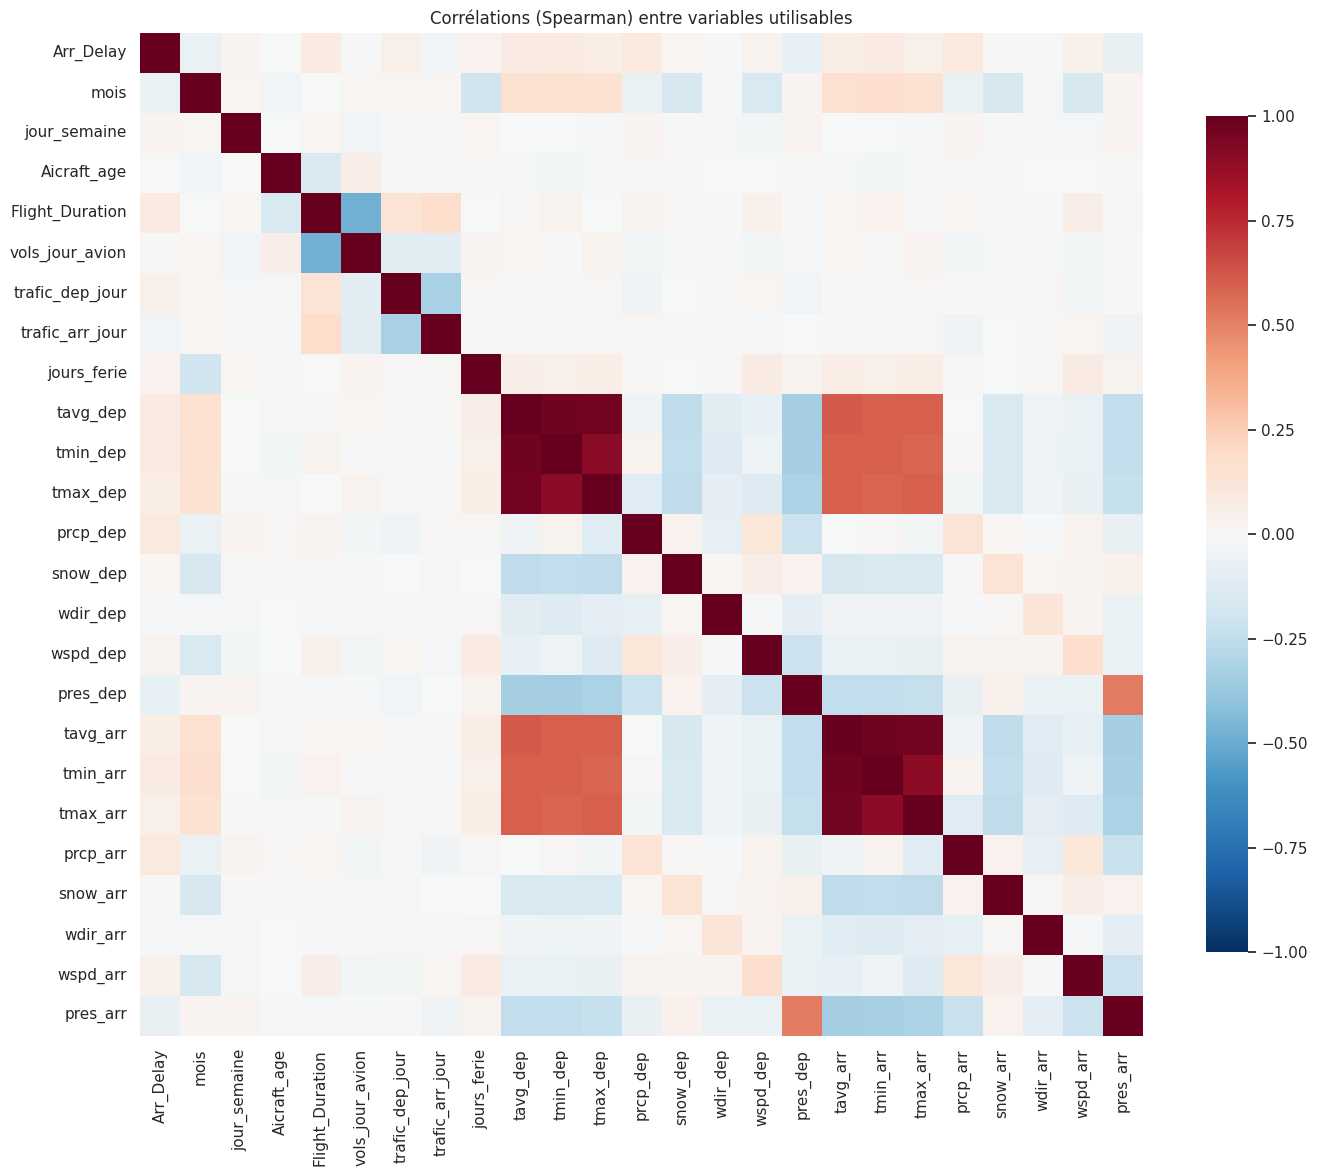

,Spearman,Pearson,utilisable
Dep_Delay,0.690,0.972,non (fuite)
Dep_Delay_Tag,0.625,0.387,non (fuite)
Delay_Carrier,0.504,0.703,non (fuite)
Delay_LastAircraft,0.488,0.606,non (fuite)
Delay_NAS,0.449,0.321,non (fuite)
Delay_Weather,0.154,0.288,non (fuite)
prcp_dep,0.100,0.073,oui
prcp_arr,0.097,0.062,oui
Flight_Duration,0.091,0.053,oui
tmin_dep,0.089,0.055,oui


Corrélations (Spearman) les plus fortes, variables utilisables : prcp_dep (+0.10), prcp_arr (+0.10), Flight_Duration (+0.09), tmin_dep (+0.09), tmin_arr (+0.08)
Corrélation du retard au départ avec la cible (fuite) : +0.69


In [14]:
CANDIDATES = ["mois", "jour_semaine", "heure_dep", C["age"], C["duree"], C["distance"],
              "vols_jour_avion", "rang_vol_jour", "trafic_dep_jour", "trafic_arr_jour", "jours_ferie"] + METEO_COLS
NUM_COLS = [c for c in dict.fromkeys(CANDIDATES) if c and c in vols and pd.api.types.is_numeric_dtype(vols[c])]
FUITE_NUM = [c for c in FUITE if pd.api.types.is_numeric_dtype(vols[c])]

ech = vols.sample(min(300_000, len(vols)), random_state=GRAINE)
corr_s = ech[[C["cible"]] + NUM_COLS + FUITE_NUM].corr(method="spearman")[C["cible"]].drop(C["cible"]).sort_values()
corr_p = ech[[C["cible"]] + NUM_COLS + FUITE_NUM].corr(method="pearson")[C["cible"]].drop(C["cible"])

fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(corr_s))))
couleurs = [ROUGE if c in FUITE_NUM else BLEU for c in corr_s.index]
ax.barh(corr_s.index, corr_s.values, color=couleurs)
ax.axvline(0, color="grey", lw=0.8)
ax.set(title="Corrélation (Spearman) avec le retard à l'arrivée\nrouge = fuite de données, exclue des modèles", xlabel="corrélation")
sauver("05_correlation_avec_cible")

if len(NUM_COLS) > 1:
    plt.figure(figsize=(min(1 + 0.55 * len(NUM_COLS), 16), min(1 + 0.5 * len(NUM_COLS), 14)))
    sns.heatmap(ech[[C["cible"]] + NUM_COLS].corr(method="spearman"), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                annot=len(NUM_COLS) <= 14, fmt=".2f", square=True, cbar_kws={"shrink": .7})
    plt.title("Corrélations (Spearman) entre variables utilisables")
    sauver("06_matrice_correlation")

tab = pd.DataFrame({"Spearman": corr_s, "Pearson": corr_p}).round(3)
tab["utilisable"] = np.where(tab.index.isin(FUITE_NUM), "non (fuite)", "oui")
display(tab.sort_values("Spearman", key=abs, ascending=False))
utiles = tab[tab["utilisable"] == "oui"]["Spearman"]
print("Corrélations (Spearman) les plus fortes, variables utilisables", ":", ", ".join(
    f"{i} ({v:+.2f})" for i, v in utiles.reindex(utiles.abs().sort_values(ascending=False).index).head(5).items()))
if C["dep_delay"] in tab.index:
    print("Corrélation du retard au départ avec la cible (fuite)", ":", f"{tab.loc[C['dep_delay'], 'Spearman']:+.2f}")

## 9. Âge de l'avion, effet domino, trafic et jours fériés

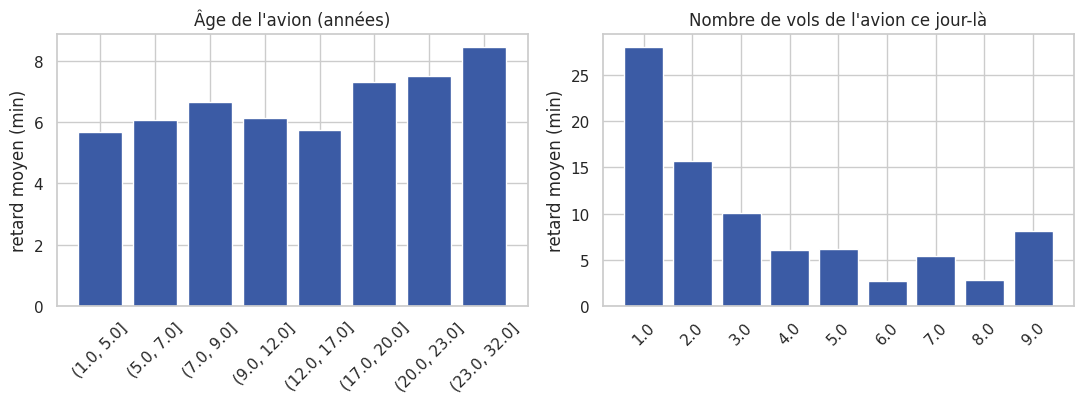

In [15]:
graphs = [g for g in [C["age"], "vols_jour_avion", "rang_vol_jour"] if g and g in vols]
if graphs:
    fig, ax = plt.subplots(1, len(graphs), figsize=(5.5 * len(graphs), 4.2))
    ax = np.atleast_1d(ax)
    for a, g in zip(ax, graphs):
        s = vols[g].clip(upper=vols[g].quantile(.99))
        grp = vols.groupby(pd.cut(s, np.unique(np.nanquantile(s, np.linspace(0, 1, 9)))) if g == C["age"] else s.round(),
                           observed=True)[C["cible"]].agg(["mean", "count"])
        grp = grp[grp["count"] >= MIN_VOLS / 10]
        a.bar(grp.index.astype(str), grp["mean"], color=BLEU)
        a.set(title={C["age"]: "Âge de l'avion (années)", "vols_jour_avion": "Nombre de vols de l'avion ce jour-là",
                     "rang_vol_jour": "Rang du vol dans la journée de l'avion"}.get(g, g), ylabel="retard moyen (min)")
        a.tick_params(axis="x", rotation=45)
    sauver("07_age_et_effet_domino")

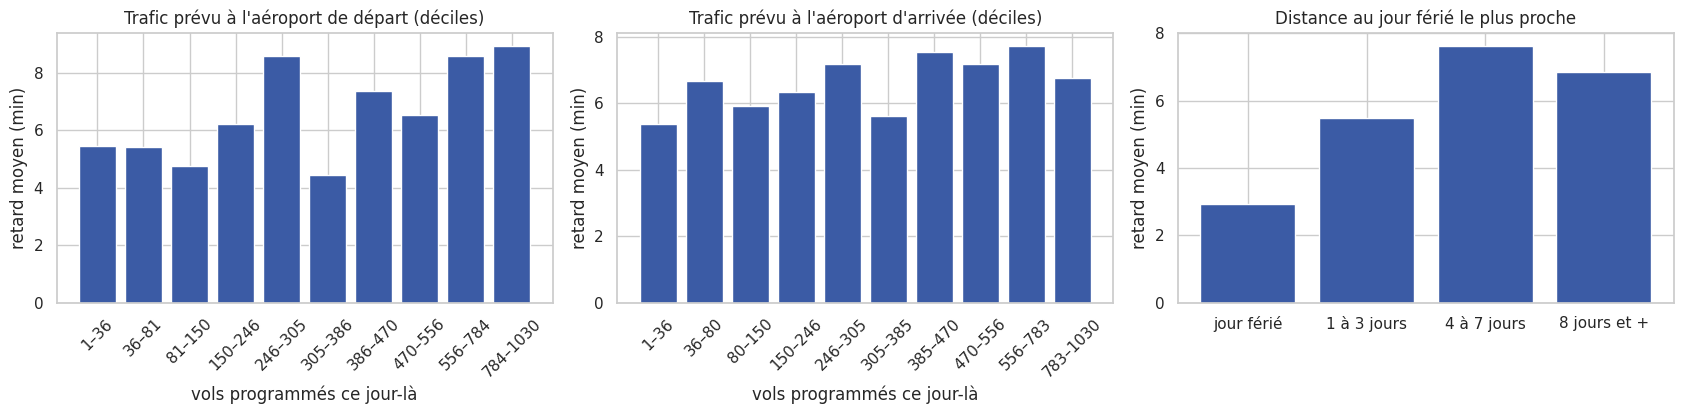

Retard moyen : 10 % des jours les plus chargés vs les moins chargés (départ) : 8.9 vs 5.5 min
Retard moyen : à 3 jours ou moins d'un jour férié vs le reste : 5.1 vs 7.0 min


,moyenne,pct
jours_ferie,,
jour férié,2.9,17.2
1 à 3 jours,5.5,19.9
4 à 7 jours,7.6,21.0
8 jours et +,6.8,20.8


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
graphes = [("trafic_dep_jour", "Trafic prévu à l'aéroport de départ (déciles)"),
           ("trafic_arr_jour", "Trafic prévu à l'aéroport d'arrivée (déciles)")]
for a, (col, titre) in zip(ax[:2], graphes):
    classes_trafic = pd.qcut(vols[col], 10, duplicates="drop")
    g = vols.groupby(classes_trafic, observed=True)[C["cible"]].agg(moyenne="mean", pct=lambda s: (s >= 15).mean() * 100)
    a.bar(range(len(g)), g["moyenne"], color=BLEU)
    a.set_xticks(range(len(g)), [f"{iv.left:.0f}–{iv.right:.0f}" for iv in g.index], rotation=45)
    a.set(title=titre, xlabel="vols programmés ce jour-là", ylabel="retard moyen (min)")
cl = pd.cut(vols["jours_ferie"], [-0.5, 0.5, 3.5, 7.5, 15.5], labels=["jour férié", "1 à 3 jours", "4 à 7 jours", "8 jours et +"])
g = vols.groupby(cl, observed=True)[C["cible"]].agg(moyenne="mean", pct=lambda s: (s >= 15).mean() * 100)
ax[2].bar(g.index.astype(str), g["moyenne"], color=BLEU)
ax[2].set(title="Distance au jour férié le plus proche", ylabel="retard moyen (min)")
sauver("07b_trafic_et_jours_feries")

t = vols["trafic_dep_jour"]
haut, bas = vols.loc[t >= t.quantile(.9), C["cible"]], vols.loc[t <= t.quantile(.1), C["cible"]]
print("Retard moyen : 10 % des jours les plus chargés vs les moins chargés (départ)", ":", f"{haut.mean():.1f} vs {bas.mean():.1f} min")
proche = vols["jours_ferie"] <= 3
print("Retard moyen : à 3 jours ou moins d'un jour férié vs le reste", ":", (
    f"{vols.loc[proche, C['cible']].mean():.1f} vs {vols.loc[~proche, C['cible']].mean():.1f} min"))
display(g.round(1))

## 10. Valeurs inhabituelles

On repère les valeurs extrêmes ou impossibles. Les retards très longs sont **réels** (ce ne sont pas des erreurs), mais ils pèsent beaucoup dans la RMSE.

,nombre de vols,% des vols
Retards au-dessus du seuil IQR (45 min),607450,9.008
Retards de plus de 5 heures (300 min),30395,0.451
Retards de plus de 24 heures (1440 min),537,0.008
Arrivées avec plus de 60 min d'avance,1453,0.022
Vols dont le départ = l'arrivée,0,0.000
Âge d'avion négatif ou > 60 ans,0,0.000
Dates illisibles,0,0.000
Météo : température min > max,4,0.000
Météo : prcp_dep négatif,0,0.000
Météo : snow_dep négatif,0,0.000


Retards au-dessus du seuil IQR : 9.0 % des vols (seuil 45 min)
Retards de plus de 5 heures : 30,395 vols


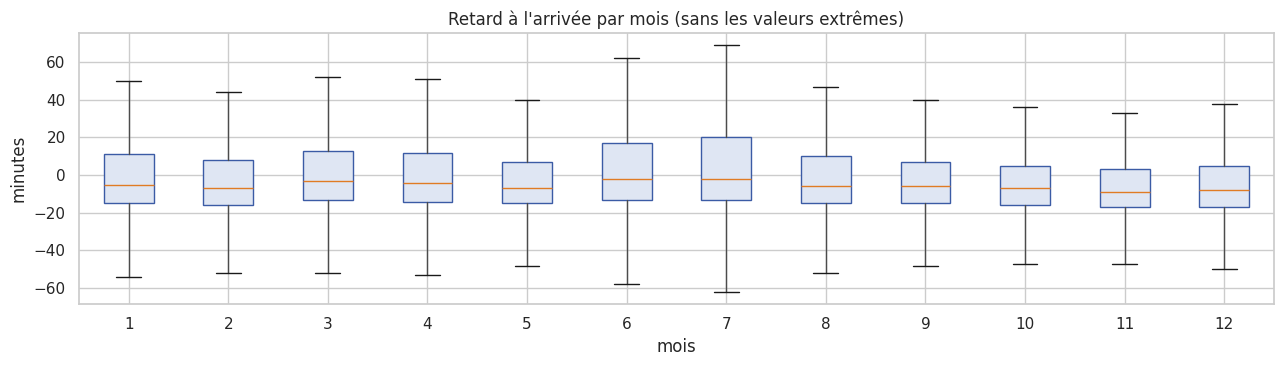

In [17]:
y = vols[C["cible"]].dropna()
q1, q3 = y.quantile([.25, .75])
seuil_haut = q3 + 1.5 * (q3 - q1)
controles = {
    f"Retards au-dessus du seuil IQR ({seuil_haut:.0f} min)": int((y > seuil_haut).sum()),
    "Retards de plus de 5 heures (300 min)": int((y > 300).sum()),
    "Retards de plus de 24 heures (1440 min)": int((y > 1440).sum()),
    "Arrivées avec plus de 60 min d'avance": int((y < -60).sum()),
}
if C["dep"] and C["arr"]:
    controles["Vols dont le départ = l'arrivée"] = int((vols[C["dep"]].astype(str) == vols[C["arr"]].astype(str)).sum())
if C["age"]:
    controles["Âge d'avion négatif ou > 60 ans"] = int(((vols[C["age"]] < 0) | (vols[C["age"]] > 60)).sum())
controles["Dates illisibles"] = int(vols["_date"].isna().sum())
if "tmin_dep" in vols and "tmax_dep" in vols:
    controles["Météo : température min > max"] = int((vols["tmin_dep"] > vols["tmax_dep"]).sum())
for v in ["prcp_dep", "snow_dep", "wspd_dep"]:
    if v in vols:
        controles[f"Météo : {v} négatif"] = int((vols[v] < 0).sum())

tab_inhab = pd.DataFrame({"nombre de vols": controles})
tab_inhab["% des vols"] = (tab_inhab["nombre de vols"] / len(vols) * 100).round(3)
display(tab_inhab)
print("Retards au-dessus du seuil IQR", ":", f"{(y > seuil_haut).mean() * 100:.1f} % des vols (seuil {seuil_haut:.0f} min)")
print("Retards de plus de 5 heures", ":", f"{int((y > 300).sum()):,} vols")

fig, ax = plt.subplots(figsize=(13, 4))
vols.boxplot(column=C["cible"], by="mois", ax=ax, showfliers=False, patch_artist=True,
             boxprops=dict(facecolor="#dfe6f3", color=BLEU), medianprops=dict(color=ORANGE))
ax.set(title="Retard à l'arrivée par mois (sans les valeurs extrêmes)", xlabel="mois", ylabel="minutes")
plt.suptitle("")
sauver("08_boites_par_mois")

## 11. Pistes d'innovation

La prédiction des retards est un sujet déjà très traité. Pour se démarquer, nous ajoutons deux volets originaux, explorés ici sans modèle (les modèles viendront au Jalon 2) :

1. **Transfert vers le Canada :** les aéroports du **nord** des États-Unis ont des hivers proches du Canada. Si leurs retards se comportent différemment de ceux du **sud**, un modèle entraîné sur un climat doux pourrait mal se transférer : c'est ce que nous testerons au Jalon 2.
2. **Prédiction par intervalle :** si les retards d'une même route varient beaucoup, un seul chiffre ne suffit pas. Il faut donner un **intervalle** (par exemple « entre 5 et 45 minutes »).

,vols,retard moyen (min),retard médian (min),% ≥ 15 min,retard moyen en hiver (min),retard moyen le reste de l'année (min),% de jours avec neige
zone,,,,,,,
Nord (climat canadien),1432916,6.0,-6.0,20.7,4.1,6.5,9.6
Sud,2413239,8.3,-4.0,22.0,5.3,9.3,0.0


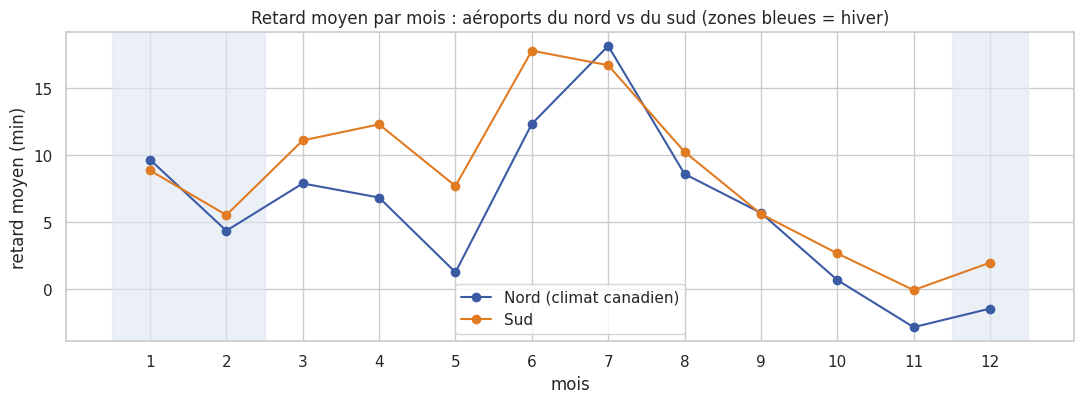

Innovation – retard moyen en hiver (nord / sud) : 4.1 / 5.3 min
Innovation – % de vols avec neige au départ (nord / sud) : 9.6 % / 0.0 %


In [18]:
NORD = ["ORD", "MDW", "MSP", "DTW", "BOS", "BUF", "CLE", "MKE", "PIT", "ROC", "SYR", "ALB", "BDL", "PVD", "PWM",
        "BTV", "MHT", "DEN", "SLC", "GRR", "MSN", "DSM", "OMA", "FAR", "FSD", "ANC"]
SUD = ["ATL", "DFW", "DAL", "IAH", "HOU", "MIA", "FLL", "MCO", "TPA", "PHX", "LAS", "LAX", "SAN", "SAT", "AUS",
       "MSY", "JAX", "RSW", "PBI", "HNL", "ONT", "SNA", "BUR", "ELP", "TUS", "OGG"]
dep_txt = vols[C["dep"]].astype(str)
zone = pd.Series(np.where(dep_txt.isin(NORD), "Nord (climat canadien)", np.where(dep_txt.isin(SUD), "Sud", None)), index=vols.index)

if zone.notna().sum() > 1000:
    z = vols.assign(zone=zone).dropna(subset=["zone"])
    hiver = z["mois"].isin([12, 1, 2])
    agg = {"vols": (C["cible"], "size"), "retard moyen (min)": (C["cible"], "mean"),
           "retard médian (min)": (C["cible"], "median"),
           "% ≥ 15 min": (C["cible"], lambda s: (s >= 15).mean() * 100)}
    comp = z.groupby("zone").agg(**agg)
    comp["retard moyen en hiver (min)"] = z[hiver].groupby("zone")[C["cible"]].mean()
    comp["retard moyen le reste de l'année (min)"] = z[~hiver].groupby("zone")[C["cible"]].mean()
    if "snow_dep" in z:
        comp["% de jours avec neige"] = z.groupby("zone")["snow_dep"].apply(lambda s: (s > 0).mean() * 100)
    display(comp.round(1))

    fig, ax = plt.subplots(figsize=(11, 4.2))
    for nom, couleur in [("Nord (climat canadien)", BLEU), ("Sud", ORANGE)]:
        m = z[z["zone"] == nom].groupby("mois")[C["cible"]].mean()
        ax.plot(m.index, m.values, "o-", color=couleur, label=nom)
    ax.axvspan(0.5, 2.5, color="#dfe6f3", alpha=.6); ax.axvspan(11.5, 12.5, color="#dfe6f3", alpha=.6)
    ax.set(title="Retard moyen par mois : aéroports du nord vs du sud (zones bleues = hiver)",
           xlabel="mois", ylabel="retard moyen (min)", xticks=range(1, 13))
    ax.legend()
    sauver("09_innovation_nord_vs_sud")
    n, s = comp.loc["Nord (climat canadien)"], comp.loc["Sud"]
    print("Innovation – retard moyen en hiver (nord / sud)", ":", f"{n['retard moyen en hiver (min)']:.1f} / {s['retard moyen en hiver (min)']:.1f} min")
    if "% de jours avec neige" in comp:
        print("Innovation – % de vols avec neige au départ (nord / sud)", ":", f"{n['% de jours avec neige']:.1f} % / {s['% de jours avec neige']:.1f} %")
else:
    print("Codes d'aéroports non reconnus (ce ne sont peut-être pas des codes IATA) : comparaison nord/sud ignorée.")

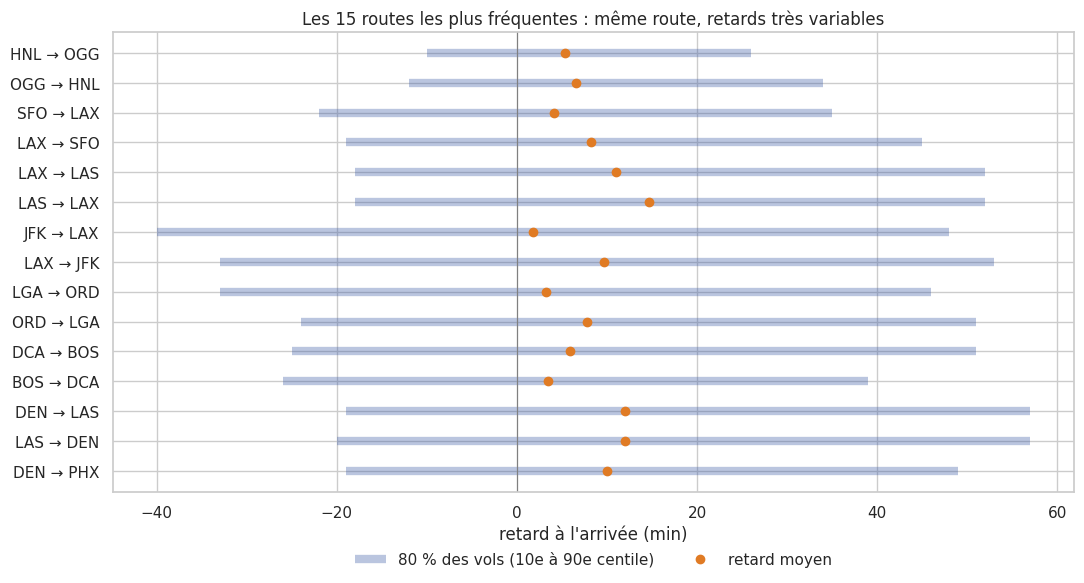

,vols,moyenne,p10,p90,largeur 10–90 % (min)
HNL → OGG,12458,5.3,-10.0,26.0,36.0
OGG → HNL,12428,6.6,-12.0,34.0,46.0
SFO → LAX,11538,4.1,-22.0,35.0,57.0
LAX → SFO,11533,8.3,-19.0,45.0,64.0
LAX → LAS,10396,11.0,-18.0,52.0,70.0
LAS → LAX,10379,14.7,-18.0,52.0,70.0
JFK → LAX,9950,1.8,-40.0,48.0,88.0
LAX → JFK,9929,9.6,-33.0,53.0,86.0
LGA → ORD,9635,3.2,-33.0,46.0,79.0
ORD → LGA,9619,7.8,-24.0,51.0,75.0


Innovation – largeur médiane de l'intervalle 10–90 % par route : 59 min (sur 5,329 routes)


In [19]:
# Dispersion des retards sur une même route : justifie la prédiction par intervalle
route = vols[C["dep"]].astype(str) + " → " + vols[C["arr"]].astype(str)
stats = vols.groupby(route)[C["cible"]].agg(vols="size", moyenne="mean",
                                            p10=lambda s: s.quantile(.1), p90=lambda s: s.quantile(.9))
stats = stats[stats["vols"] >= max(30, MIN_VOLS // 10)]
stats["largeur 10–90 % (min)"] = stats["p90"] - stats["p10"]
top = stats.sort_values("vols", ascending=False).head(15)[::-1]

fig, ax = plt.subplots(figsize=(11, 6))
ax.hlines(top.index, top["p10"], top["p90"], color=BLEU, lw=6, alpha=.35, label="80 % des vols (10e à 90e centile)")
ax.plot(top["moyenne"], top.index, "o", color=ORANGE, label="retard moyen")
ax.axvline(0, color="grey", lw=.8)
ax.set(title="Les 15 routes les plus fréquentes : même route, retards très variables", xlabel="retard à l'arrivée (min)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
sauver("10_innovation_dispersion_par_route")
display(top[::-1].round(1))
print("Innovation – largeur médiane de l'intervalle 10–90 % par route", ":", f"{stats['largeur 10–90 % (min)'].median():.0f} min (sur {len(stats):,} routes)")

## 12. Dictionnaire de données

Le dictionnaire est généré automatiquement : nom réel de chaque colonne, type, description, exemple, valeurs manquantes et rôle. Il est enregistré dans `dictionnaire_donnees.csv`, qui s'ouvre dans Excel.

> Vérifiez les lignes marquées « à vérifier » et « à compléter ».

In [20]:
DESCRIPTIONS = {
    "flightdate": "Date du vol", "fldate": "Date du vol", "dayofweek": "Jour de la semaine (1 = lundi)",
    "airline": "Compagnie aérienne", "carrier": "Compagnie aérienne", "tailnumber": "Immatriculation de l'avion",
    "depairport": "Aéroport de départ (code)", "origin": "Aéroport de départ (code)",
    "depcityname": "Ville de départ", "deptimelabel": "Moment de la journée du départ",
    "depdelay": "Retard au départ (minutes)", "depdelaytag": "Indicateur de retard au départ",
    "depdelaytype": "Catégorie du retard au départ", "arrairport": "Aéroport d'arrivée (code)",
    "dest": "Aéroport d'arrivée (code)", "arrcityname": "Ville d'arrivée",
    "arrdelay": "Retard à l'arrivée (minutes) – variable cible", "arrdelaytype": "Catégorie du retard à l'arrivée",
    "flightduration": "Durée du vol (minutes)", "distancetype": "Catégorie de distance du vol",
    "distance": "Distance du vol (milles)", "delaycarrier": "Minutes de retard dues à la compagnie",
    "delayweather": "Minutes de retard dues à la météo", "delaynas": "Minutes de retard dues au système aérien",
    "delaysecurity": "Minutes de retard dues à la sécurité", "delaylastaircraft": "Minutes de retard dues à l'avion précédent",
    "manufacturer": "Constructeur de l'avion", "model": "Modèle de l'avion", "aicraftage": "Âge de l'avion (années)",
    "aircraftage": "Âge de l'avion (années)",
    "mois": "Mois du vol (créée)", "joursemaine": "Jour de la semaine, 1 = lundi (créée)",
    "heuredep": "Heure de départ prévue (créée)", "tranche": "Moment de la journée (créée)",
    "volsjouravion": "Nombre de vols du même avion ce jour-là (créée)",
    "rangvoljour": "Rang du vol dans la journée de l'avion (créée)",
    "traficdepjour": "Nombre de vols programmés ce jour-là à l'aéroport de départ (créée)",
    "traficarrjour": "Nombre de vols programmés ce jour-là à l'aéroport d'arrivée (créée)",
    "joursferie": "Nombre de jours jusqu'au jour férié américain le plus proche, plafonné à 15 (créée)",
}
METEO_DESC = {"tavg": "Température moyenne (°C)", "tmin": "Température minimale (°C)", "tmax": "Température maximale (°C)",
              "prcp": "Précipitations (mm)", "snow": "Neige (mm)", "wdir": "Direction du vent (degrés)",
              "wspd": "Vitesse du vent (km/h)", "pres": "Pression (hPa)"}
for v in VARS_METEO:
    for cote, lieu in [("dep", "à l'aéroport de départ"), ("arr", "à l'aéroport d'arrivée")]:
        DESCRIPTIONS[norm(f"{v}_{cote}")] = f"{METEO_DESC.get(v, v)} {lieu} (jointe)"

REDONDANTES = [c for c in vols.columns if re.search(r"cityname|city_name", c, re.I)]
CAUSES = [c for c in vols.columns if re.search(r"^delay_|_delay$", c, re.I) and c not in (C["cible"], C["dep_delay"])]

def role(c):
    if c == C["cible"]:
        return "Oui (cible)"
    if c in CAUSES:
        return "Analyse seulement (fuite)"
    if c in FUITE:
        return "Non (fuite de données)"
    if c == C["avion"]:
        return "Non (sert à créer vols_jour_avion)"
    if c in REDONDANTES:
        return "Non (redondant avec l'aéroport)"
    if c == C["date"]:
        return "Oui (via mois et jour_semaine)"
    if c in (C["duree"], C["heure"]):
        return "À vérifier (prévue ou réelle ?)"
    return "Oui"

def type_fr(s):
    if pd.api.types.is_datetime64_any_dtype(s):
        return "Date"
    if pd.api.types.is_numeric_dtype(s):
        return "Binaire" if s.dropna().isin([0, 1]).all() and s.nunique() <= 2 else "Numérique"
    return "Date" if s.name == C["date"] else "Catégorielle"

colonnes = [c for c in vols.columns if not c.startswith("_")]
dico = pd.DataFrame({
    "Variable": colonnes,
    "Type": [type_fr(vols[c]) for c in colonnes],
    "Description": [DESCRIPTIONS.get(norm(c), "à compléter") for c in colonnes],
    "Exemple": [(round(float(v), 2) if isinstance(v, (float, np.floating)) else v) for v in (vols[c].dropna().iloc[0] if vols[c].notna().any() else "" for c in colonnes)],
    "Manquantes (%)": [round(vols[c].isna().mean() * 100, 2) for c in colonnes],
    "Valeurs distinctes": [int(vols[c].nunique()) for c in colonnes],
    "Utilisée ?": [role(c) for c in colonnes],
})
dico.to_csv("dictionnaire_donnees.csv", index=False, encoding="utf-8-sig")
display(dico)
print("Variables dans le dictionnaire", ":", f"{len(dico)} (dont {int((dico['Utilisée ?'].str.startswith('Oui')).sum())} utilisables pour prédire)")

,Variable,Type,Description,Exemple,Manquantes (%),Valeurs distinctes,Utilisée ?
0,FlightDate,Date,Date du vol,2023-01-02,0.0,365,Oui (via mois et jour_semaine)
1,Day_Of_Week,Numérique,Jour de la semaine (1 = lundi),1,0.0,7,Oui
2,Airline,Catégorielle,Compagnie aérienne,Endeavor Air,0.0,15,Oui
3,Tail_Number,Catégorielle,Immatriculation de l'avion,N605LR,0.0,5963,Non (sert à créer vols_jour_avion)
4,Dep_Airport,Catégorielle,Aéroport de départ (code),BDL,0.0,350,Oui
5,Dep_CityName,Catégorielle,Ville de départ,"Hartford, CT",0.0,344,Non (redondant avec l'aéroport)
6,DepTime_label,Catégorielle,Moment de la journée du départ,Morning,0.0,4,À vérifier (prévue ou réelle ?)
7,Dep_Delay,Numérique,Retard au départ (minutes),-3,0.0,1854,Non (fuite de données)
8,Dep_Delay_Tag,Binaire,Indicateur de retard au départ,0,0.0,2,Non (fuite de données)
9,Dep_Delay_Type,Catégorielle,Catégorie du retard au départ,Low <5min,0.0,3,Non (fuite de données)


Variables dans le dictionnaire : 47 (dont 33 utilisables pour prédire)


## 13. Préparation des données (partie 1) : nettoyage de base

Chaque étape est notée dans un **journal de nettoyage**, utile pour le journal de projet. Le fichier préparé ne garde que les colonnes utiles à la modélisation ; les causes de retard restent dans le fichier d'origine pour l'analyse.

In [21]:
journal = []
def etape(nom, avant, apres, detail=""):
    journal.append({"étape": nom, "vols avant": avant, "vols après": apres, "retirés": avant - apres, "détail": detail})

prep = vols
n = len(prep); prep = prep.drop_duplicates(subset=[c for c in prep.columns if not c.startswith("_")])
etape("Suppression des doublons", n, len(prep))
n = len(prep); prep = prep.dropna(subset=[C["cible"]])
etape("Suppression des vols sans retard à l'arrivée", n, len(prep), "annulés ou déroutés restants")
n = len(prep); prep = prep[prep["_date"].notna()]
etape("Suppression des dates illisibles", n, len(prep))
if C["dep"] and C["arr"]:
    n = len(prep); prep = prep[prep[C["dep"]].astype(str) != prep[C["arr"]].astype(str)]
    etape("Suppression des vols départ = arrivée", n, len(prep))
if C["age"]:
    impossibles = int(((prep[C["age"]] < 0) | (prep[C["age"]] > 60)).sum())
    prep.loc[(prep[C["age"]] < 0) | (prep[C["age"]] > 60), C["age"]] = np.nan
    etape("Âges impossibles remplacés par une valeur manquante", len(prep), len(prep), f"{impossibles} valeurs")

retirer = [c for c in FUITE + REDONDANTES + [C["avion"]] if c and c in prep]
garder = [c for c in prep.columns if c not in retirer and not c.startswith("_")]
prep = prep[garder].copy()
etape("Colonnes retirées (fuite, redondantes, identifiant)", len(prep), len(prep), ", ".join(retirer))

for c in prep.select_dtypes("float64").columns:
    prep[c] = prep[c].astype("float32")
for c in prep.select_dtypes("object").columns:
    prep[c] = prep[c].astype("category")

journal = pd.DataFrame(journal)
display(journal)
print(f"Données préparées : {len(prep):,} vols × {prep.shape[1]} colonnes – {prep.memory_usage(deep=True).sum()/1e9:.2f} Go")
print("Colonnes gardées :", list(prep.columns))

prep.to_parquet("vols_prepares.parquet", index=False)
journal.to_csv("journal_nettoyage.csv", index=False, encoding="utf-8-sig")
print("Vols après nettoyage", ":", f"{len(prep):,} ({(1 - len(prep) / len(vols)) * 100:.2f} % retirés)")
print("Colonnes retirées", ":", ", ".join(retirer))
print("\nFichiers créés : vols_prepares.parquet, journal_nettoyage.csv")

,étape,vols avant,vols après,retirés,détail
0,Suppression des doublons,6743404,6743373,31,
1,Suppression des vols sans retard à l'arrivée,6743373,6743373,0,annulés ou déroutés restants
2,Suppression des dates illisibles,6743373,6743373,0,
3,Suppression des vols départ = arrivée,6743373,6743373,0,
4,Âges impossibles remplacés par une valeur manq...,6743373,6743373,0,0 valeurs
5,"Colonnes retirées (fuite, redondantes, identif...",6743373,6743373,0,"Dep_Delay, Dep_Delay_Tag, Dep_Delay_Type, Arr_..."


Données préparées : 6,743,373 vols × 35 colonnes – 0.94 Go
Colonnes gardées : ['FlightDate', 'Day_Of_Week', 'Airline', 'Dep_Airport', 'DepTime_label', 'Arr_Airport', 'Arr_Delay', 'Flight_Duration', 'Distance_type', 'Manufacturer', 'Model', 'Aicraft_age', 'mois', 'jour_semaine', 'tranche', 'vols_jour_avion', 'trafic_dep_jour', 'trafic_arr_jour', 'jours_ferie', 'tavg_dep', 'tmin_dep', 'tmax_dep', 'prcp_dep', 'snow_dep', 'wdir_dep', 'wspd_dep', 'pres_dep', 'tavg_arr', 'tmin_arr', 'tmax_arr', 'prcp_arr', 'snow_arr', 'wdir_arr', 'wspd_arr', 'pres_arr']
Vols après nettoyage : 6,743,373 (0.00 % retirés)
Colonnes retirées : Dep_Delay, Dep_Delay_Tag, Dep_Delay_Type, Arr_Delay_Type, Delay_Carrier, Delay_Weather, Delay_NAS, Delay_Security, Delay_LastAircraft, Dep_CityName, Arr_CityName, Tail_Number

Fichiers créés : vols_prepares.parquet, journal_nettoyage.csv


## 14. Fichiers produits

Les graphiques sont regroupés dans `figures_predivol.zip`. **Pensez à sauvegarder** : les fichiers de Colab sont effacés à la fermeture. Copiez `vols_prepares.parquet` dans votre Google Drive pour le Jalon 2.

In [22]:
shutil.make_archive("figures_predivol", "zip", "figures")
try:
    from google.colab import files
    for nom in ["figures_predivol.zip", "dictionnaire_donnees.csv", "journal_nettoyage.csv"]:
        files.download(nom)
except Exception:
    print("Fichiers créés : figures_predivol.zip, dictionnaire_donnees.csv, journal_nettoyage.csv, vols_prepares.parquet")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# from google.colab import drive
# import os, shutil
# drive.mount("/content/drive")
# os.makedirs("/content/drive/MyDrive/predivol", exist_ok=True)
# shutil.copy("vols_prepares.parquet", "/content/drive/MyDrive/predivol/vols_prepares.parquet")
# print("Fichier copié dans Google Drive : MyDrive/predivol/vols_prepares.parquet")

# Partie 2 – Prétraitement, séparation des données et premiers modèles

In [24]:
# Bibliothèques de modélisation
import os, time, json, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
os.makedirs("figures_jalon2", exist_ok=True)
BLEU, ORANGE, GRIS = "#3b5ba5", "#e07b24", "#9aa3b2"

def sauver(nom):
    plt.tight_layout(); plt.savefig(f"figures_jalon2/{nom}.png", dpi=130, bbox_inches="tight"); plt.show()

In [25]:
import gc
for nom in ["vols", "prep", "meteo", "y"]:      # libère la mémoire de la partie 1
    globals().pop(nom, None)
gc.collect()

vols = pd.read_parquet("vols_prepares.parquet")
print(f"{len(vols):,} vols × {vols.shape[1]} colonnes")
print(list(vols.columns))

6,743,373 vols × 35 colonnes
['FlightDate', 'Day_Of_Week', 'Airline', 'Dep_Airport', 'DepTime_label', 'Arr_Airport', 'Arr_Delay', 'Flight_Duration', 'Distance_type', 'Manufacturer', 'Model', 'Aicraft_age', 'mois', 'jour_semaine', 'tranche', 'vols_jour_avion', 'trafic_dep_jour', 'trafic_arr_jour', 'jours_ferie', 'tavg_dep', 'tmin_dep', 'tmax_dep', 'prcp_dep', 'snow_dep', 'wdir_dep', 'wspd_dep', 'pres_dep', 'tavg_arr', 'tmin_arr', 'tmax_arr', 'prcp_arr', 'snow_arr', 'wdir_arr', 'wspd_arr', 'pres_arr']


## 16. Prétraitement : choix des variables

- **Cible :** `Arr_Delay` (minutes).
- **Variables catégorielles :** compagnie, aéroports, moment de la journée, catégorie de distance, constructeur et modèle d'avion.
- **Variables numériques :** mois, jour de la semaine, âge de l'avion, effet domino, trafic prévu, jours fériés, météo au départ et à l'arrivée.
- **Exclues :** la date (elle sert seulement à séparer les données), `Day_Of_Week` (doublon de `jour_semaine`), `tranche` (doublon de `DepTime_label`) et `Flight_Duration` (probablement la durée réelle, donc une fuite possible).

L'encodage et l'imputation sont faits **dans des pipelines** et appris **sur l'entraînement seulement**, pour éviter toute fuite d'information vers la validation et le test.

In [26]:
# ===== PARAMÈTRES DE LA PARTIE 2 =====
TAILLE_ECHANTILLON = 1_200_000   # nombre total de vols utilisés (entraînement + validation + test)
UTILISER_DUREE = False           # Flight_Duration est probablement la durée RÉELLE : exclue (fuite de données)
SEUIL_GROS_RETARD = 60           # minutes : définition d'un « gros retard »
PART_SIGNALEE = 0.10             # part des vols signalés « à risque » (10 %)
GRAINE = 42

In [27]:
def trouver(*noms):
    bas = {c.lower(): c for c in vols.columns}
    for n in noms:
        if n.lower() in bas: return bas[n.lower()]
    return None

CIBLE = trouver("Arr_Delay", "ARRIVAL_DELAY")
DATE = trouver("FlightDate", "FL_DATE")
DEP, ARR = trouver("Dep_Airport", "Origin"), trouver("Arr_Airport", "Dest")
assert CIBLE and DATE and DEP and ARR

CAT = [c for c in [trouver("Airline"), DEP, ARR, trouver("DepTime_label") or ("tranche" if "tranche" in vols else None),
                   trouver("Distance_type"), trouver("Manufacturer"), trouver("Model")] if c]
METEO = [c for c in vols.columns if c.endswith("_dep") or c.endswith("_arr")]
METEO = [c for c in METEO if c not in ("trafic_dep_jour", "trafic_arr_jour") and pd.api.types.is_numeric_dtype(vols[c])]
NUM = [c for c in ["mois", "jour_semaine", trouver("Aicraft_age", "Aircraft_age"), "vols_jour_avion",
                   "trafic_dep_jour", "trafic_arr_jour", "jours_ferie"] if c and c in vols] + METEO
if UTILISER_DUREE and trouver("Flight_Duration"):
    NUM.append(trouver("Flight_Duration"))

print("Catégorielles :", CAT)
print("Numériques    :", NUM)
print(f"Total : {len(CAT) + len(NUM)} variables explicatives")

vols = vols.dropna(subset=[CIBLE])

Catégorielles : ['Airline', 'Dep_Airport', 'Arr_Airport', 'DepTime_label', 'Distance_type', 'Manufacturer', 'Model']
Numériques    : ['mois', 'jour_semaine', 'Aicraft_age', 'vols_jour_avion', 'trafic_dep_jour', 'trafic_arr_jour', 'jours_ferie', 'tavg_dep', 'tmin_dep', 'tmax_dep', 'prcp_dep', 'snow_dep', 'wdir_dep', 'wspd_dep', 'pres_dep', 'tavg_arr', 'tmin_arr', 'tmax_arr', 'prcp_arr', 'snow_arr', 'wdir_arr', 'wspd_arr', 'pres_arr']
Total : 30 variables explicatives


## 17. Séparation entraînement / validation / test (70 / 15 / 15)

In [28]:
rng = np.random.default_rng(GRAINE)
jours = pd.Series(pd.to_datetime(vols[DATE].astype(str)).dt.normalize().unique())
jours = jours.sample(frac=1, random_state=GRAINE).reset_index(drop=True)
n = len(jours)
ensemble_du_jour = pd.Series("test", index=jours.values)
ensemble_du_jour.iloc[: int(.70 * n)] = "entraînement"
ensemble_du_jour.iloc[int(.70 * n): int(.85 * n)] = "validation"
vols["ensemble"] = pd.to_datetime(vols[DATE].astype(str)).dt.normalize().map(ensemble_du_jour)

fraction = min(1.0, TAILLE_ECHANTILLON / len(vols))
ech = vols.groupby("ensemble", group_keys=False).sample(frac=fraction, random_state=GRAINE)
for c in CAT:                                     # texte seulement sur l'échantillon (économise la mémoire)
    ech[c] = ech[c].astype(str)
train, val, test = (ech[ech["ensemble"] == e] for e in ["entraînement", "validation", "test"])
X_tr, y_tr = train[CAT + NUM], train[CIBLE].astype(float)
X_va, y_va = val[CAT + NUM], val[CIBLE].astype(float)

resume_split = pd.DataFrame({
    "jours": vols.groupby("ensemble")[DATE].nunique(),
    "vols utilisés": ech["ensemble"].value_counts(),
    "retard moyen (min)": ech.groupby("ensemble")[CIBLE].mean().round(2),
    "% ≥ 15 min": ech.groupby("ensemble")[CIBLE].apply(lambda s: (s >= 15).mean() * 100).round(1),
}).loc[["entraînement", "validation", "test"]]
display(resume_split)
print(f"Échantillon : {fraction * 100:.1f} % des vols. Les trois ensembles ont des distributions proches : la séparation est équilibrée.")

,jours,vols utilisés,retard moyen (min),% ≥ 15 min
ensemble,,,,
entraînement,255,836906,6.75,20.7
validation,55,180979,5.62,19.7
test,55,182115,6.85,20.8


Échantillon : 17.8 % des vols. Les trois ensembles ont des distributions proches : la séparation est équilibrée.


## 18. Mesures de performance et modèles de référence

In [29]:
def mesurer(nom, y, p, t_fit=np.nan, t_pred=np.nan):
    y, p = np.asarray(y, float), np.asarray(p, float)
    gros = y >= SEUIL_GROS_RETARD
    k = int(round(PART_SIGNALEE * len(p)))              # exactement 10 % des vols signalés
    bruit = np.random.default_rng(GRAINE).random(len(p)) * 1e-9   # départage les égalités au hasard
    signale = np.zeros(len(p), bool); signale[np.argsort(-(p + bruit))[:k]] = True
    return {
        "modèle": nom,
        "MAE (min)": mean_absolute_error(y, p),
        "RMSE (min)": mean_squared_error(y, p) ** 0.5,
        "R²": r2_score(y, p),
        f"capture gros retards (%)": (signale & gros).sum() / max(gros.sum(), 1) * 100,
        "prédictions à ±15 min (%)": (np.abs(y - p) <= 15).mean() * 100,
        "entraînement (s)": t_fit,
        "prédiction / 1 000 vols (ms)": t_pred,
    }

resultats, predictions = [], {}

# Référence 1 : moyenne globale
p = np.full(len(y_va), y_tr.mean())
resultats.append(mesurer("Naïf – moyenne globale", y_va, p)); predictions["Naïf – moyenne globale"] = p

# Référence 2 : moyenne historique de la route (critère du cahier des charges)
route = lambda d: d[DEP] + "→" + d[ARR]
moy_route, moy_dep = y_tr.groupby(route(train)).mean(), y_tr.groupby(train[DEP]).mean()
p = route(val).map(moy_route).fillna(val[DEP].map(moy_dep)).fillna(y_tr.mean()).to_numpy(float)
resultats.append(mesurer("Naïf – moyenne de la route", y_va, p)); predictions["Naïf – moyenne de la route"] = p
MAE_NAIF = resultats[-1]["MAE (min)"]
pd.DataFrame(resultats).round(2)

,modèle,MAE (min),RMSE (min),R²,capture gros retards (%),prédictions à ±15 min (%),entraînement (s),prédiction / 1 000 vols (ms)
0,Naïf – moyenne globale,25.78,55.28,-0.0,10.13,40.67,NaN,NaN
1,Naïf – moyenne de la route,25.70,55.27,-0.0,15.79,42.94,NaN,NaN


## 19. Modèles de régression

| Modèle | Pourquoi l'essayer ? |
| --- | --- |
| **Ridge** (régression linéaire régularisée) | Simple, rapide et interprétable : la référence « linéaire » |
| **Forêt aléatoire** | Capte les interactions (ex. soir × été) ; robuste aux valeurs extrêmes |
| **Gradient boosting** (`HistGradientBoostingRegressor`) | Très performant sur les données tabulaires, rapide sur des millions de lignes |
| **XGBoost** | Gradient boosting de référence dans l'industrie, à comparer avec celui de scikit-learn |

In [30]:
prep_lineaire = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200), CAT),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("std", StandardScaler())]), NUM),
])
def prep_arbres(imputer):
    cat = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan,
                         max_categories=250, dtype=float)
    etapes_cat = [("ord", cat)] + ([("imp", SimpleImputer(strategy="constant", fill_value=-1))] if imputer else [])
    etapes_num = [("imp", SimpleImputer(strategy="median"))] if imputer else "passthrough"
    return ColumnTransformer([("cat", Pipeline(etapes_cat), CAT),
                              ("num", Pipeline(etapes_num) if imputer else "passthrough", NUM)])

IDX_CAT = list(range(len(CAT)))
modeles = {
    "Ridge": Pipeline([("prep", prep_lineaire), ("mod", Ridge(alpha=1.0))]),
    "Forêt aléatoire": Pipeline([("prep", prep_arbres(True)),
                                 ("mod", RandomForestRegressor(n_estimators=100, max_depth=18, min_samples_leaf=20,
                                                               max_samples=min(200_000, len(X_tr)), max_features=0.5,
                                                               n_jobs=-1, random_state=GRAINE))]),
    "Gradient boosting": Pipeline([("prep", prep_arbres(False)),
                                   ("mod", HistGradientBoostingRegressor(categorical_features=IDX_CAT, max_iter=500,
                                                                         learning_rate=0.08, max_leaf_nodes=63,
                                                                         early_stopping=True, random_state=GRAINE))]),
}
try:
    from xgboost import XGBRegressor
    modeles["XGBoost"] = Pipeline([("prep", prep_arbres(False)),
                                   ("mod", XGBRegressor(n_estimators=500, learning_rate=0.08, max_depth=8, subsample=0.8,
                                                        colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                                                        random_state=GRAINE))])
except ImportError:
    print("XGBoost non installé : %pip install xgboost pour l'ajouter.")

entraines = {}
for nom, pipe in modeles.items():
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); p = pipe.predict(X_va); t_pred = (time.perf_counter() - t0) / len(X_va) * 1000 * 1000
    entraines[nom], predictions[nom] = pipe, p
    resultats.append(mesurer(nom, y_va, p, t_fit, t_pred))
    print(f"{nom:20s} MAE = {resultats[-1]['MAE (min)']:.2f} min   ({t_fit:.0f} s d'entraînement)")

Ridge                MAE = 24.91 min   (25 s d'entraînement)
Forêt aléatoire      MAE = 24.36 min   (216 s d'entraînement)
Gradient boosting    MAE = 24.43 min   (32 s d'entraînement)
XGBoost              MAE = 25.10 min   (63 s d'entraînement)


## 20. Comparaison des modèles (jeu de validation)


,modèle,MAE (min),RMSE (min),R²,capture gros retards (%),prédictions à ±15 min (%),entraînement (s),prédiction / 1 000 vols (ms),gain MAE vs naïf route
0,Naïf – moyenne globale,25.78,55.28,-0.00,10.13,40.67,NaN,NaN,-0.3 %
1,Naïf – moyenne de la route,25.70,55.27,-0.00,15.79,42.94,NaN,NaN,0.0 %
2,Ridge,24.91,54.11,0.04,29.07,45.25,25.02,3.23,3.1 %
3,Forêt aléatoire,24.36,53.50,0.06,32.49,48.13,215.98,12.24,5.2 %
4,Gradient boosting,24.43,53.58,0.06,32.13,49.81,32.44,30.63,4.9 %
5,XGBoost,25.10,54.05,0.04,32.29,48.91,63.35,12.59,2.3 %


Meilleur modèle sur la validation (MAE) : Forêt aléatoire


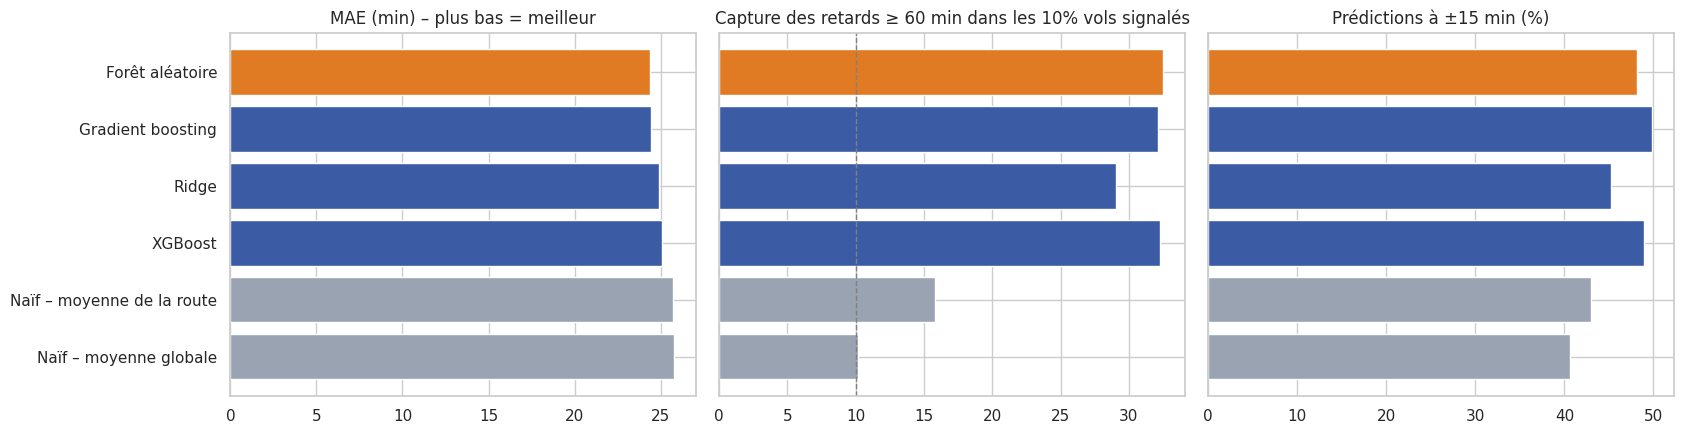

In [31]:
res = pd.DataFrame(resultats)
res["gain MAE vs naïf route"] = ((1 - res["MAE (min)"] / MAE_NAIF) * 100).round(1).astype(str) + " %"
display(res.round(2))

candidats = res[~res["modèle"].str.startswith("Naïf")].sort_values("MAE (min)")
MEILLEUR = candidats.iloc[0]["modèle"]
print(f"Meilleur modèle sur la validation (MAE) : {MEILLEUR}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ordre = res.sort_values("MAE (min)", ascending=False)
couleurs = [GRIS if m.startswith("Naïf") else (ORANGE if m == MEILLEUR else BLEU) for m in ordre["modèle"]]
ax[0].barh(ordre["modèle"], ordre["MAE (min)"], color=couleurs); ax[0].set(title="MAE (min) – plus bas = meilleur")
ax[1].barh(ordre["modèle"], ordre["capture gros retards (%)"], color=couleurs)
ax[1].axvline(PART_SIGNALEE * 100, color="grey", ls="--", lw=1)
ax[1].set(title=f"Capture des retards ≥ {SEUIL_GROS_RETARD} min dans les {PART_SIGNALEE:.0%} vols signalés")
ax[2].barh(ordre["modèle"], ordre["prédictions à ±15 min (%)"], color=couleurs); ax[2].set(title="Prédictions à ±15 min (%)")
for a in ax[1:]: a.set_yticklabels([])
sauver("01_comparaison_modeles")

## 20 bis. Choix de la métrique : comparaison des métriques

Avant de fixer les cibles du contrat d'optimisation, on compare plusieurs métriques de régression sur les mêmes prédictions (jeu de validation) :

- **MAE** : erreur moyenne en minutes ;
- **RMSE** : erreur qui pénalise fortement les grosses erreurs ;
- **R²** : part de la variation des retards expliquée par le modèle ;
- **erreur médiane (MedAE)** : erreur sur un vol « typique » ;
- **MAPE** : erreur en pourcentage du retard réel.

On regarde aussi si les métriques classent les modèles dans le même ordre.

In [32]:
from sklearn.metrics import median_absolute_error

# 1. Forme des retards : pourquoi certaines métriques conviennent mal
y = y_va.to_numpy(float)
print(f"Retards de la validation : moyenne {y.mean():.1f} min, médiane {np.median(y):.1f} min, maximum {y.max():.0f} min")
print(f"Vols en avance ou à l'heure (retard ≤ 0) : {(y <= 0).mean() * 100:.1f} %  –  retard exactement 0 : {(y == 0).mean() * 100:.1f} %")
print("→ Distribution très asymétrique ; la MAPE (division par le retard réel) est impossible quand le retard vaut 0.\n")

# 2. Toutes les métriques, pour chaque modèle
lignes = []
for nom, p in predictions.items():
    lignes.append({
        "modèle": nom,
        "MAE (min)": mean_absolute_error(y, p),
        "RMSE (min)": mean_squared_error(y, p) ** 0.5,
        "RMSE / MAE": mean_squared_error(y, p) ** 0.5 / mean_absolute_error(y, p),
        "R²": r2_score(y, p),
        "erreur médiane (min)": median_absolute_error(y, p),
        "MAPE": "impossible (retards = 0)",
    })
comp_metriques = pd.DataFrame(lignes).sort_values("MAE (min)")
display(comp_metriques.round(2))

# 3. Les métriques classent-elles les modèles de la même façon ?
rangs = pd.DataFrame({
    "rang MAE": comp_metriques["MAE (min)"].rank(),
    "rang RMSE": comp_metriques["RMSE (min)"].rank(),
    "rang R²": comp_metriques["R²"].rank(ascending=False),
    "rang erreur médiane": comp_metriques["erreur médiane (min)"].rank(),
}).astype(int)
rangs.insert(0, "modèle", comp_metriques["modèle"])
display(rangs)

# 4. Tableau de décision : quelle métrique retenir ?
b = comp_metriques.set_index("modèle").loc[MEILLEUR]
choix = pd.DataFrame([
    ["MAE", f"{b['MAE (min)']:.2f} min", "En minutes, facile à comprendre ; peu sensible aux retards extrêmes",
     "Pénalise peu les très grosses erreurs", "Retenue : technique primaire"],
    ["RMSE", f"{b['RMSE (min)']:.2f} min", "Pénalise les grosses erreurs, les plus coûteuses",
     f"Dominée par quelques retards extrêmes (RMSE = {b['RMSE / MAE']:.1f} × MAE)", "Retenue : technique secondaire (garde-fou)"],
    ["R²", f"{b['R²']:.3f}", "Utile pour comparer des modèles entre eux",
     "Peu parlant pour le client ; faible sans le retard au départ (exclu : fuite)", "Non retenue (suivie)"],
    ["Erreur médiane", f"{b['erreur médiane (min)']:.2f} min", "Erreur d'un vol typique",
     "Ignore complètement les gros retards", "Non retenue"],
    ["MAPE", "impossible", "Facile à lire en %",
     f"{(y == 0).mean() * 100:.1f} % des retards valent 0 : division par 0", "Non retenue"],
], columns=["métrique", f"valeur ({MEILLEUR})", "avantage", "limite pour PrédiVol", "décision"])
display(choix)
choix.to_csv("comparaison_metriques.csv", index=False, encoding="utf-8-sig")
print("Tableau enregistré : comparaison_metriques.csv")

Retards de la validation : moyenne 5.6 min, médiane -6.0 min, maximum 3246 min
Vols en avance ou à l'heure (retard ≤ 0) : 64.4 %  –  retard exactement 0 : 1.9 %
→ Distribution très asymétrique ; la MAPE (division par le retard réel) est impossible quand le retard vaut 0.



,modèle,MAE (min),RMSE (min),RMSE / MAE,R²,erreur médiane (min),MAPE
3,Forêt aléatoire,24.36,53.50,2.20,0.06,15.65,impossible (retards = 0)
4,Gradient boosting,24.43,53.58,2.19,0.06,15.07,impossible (retards = 0)
2,Ridge,24.91,54.11,2.17,0.04,16.72,impossible (retards = 0)
5,XGBoost,25.10,54.05,2.15,0.04,15.40,impossible (retards = 0)
1,Naïf – moyenne de la route,25.70,55.27,2.15,-0.00,17.37,impossible (retards = 0)
0,Naïf – moyenne globale,25.78,55.28,2.14,-0.00,17.75,impossible (retards = 0)


,modèle,rang MAE,rang RMSE,rang R²,rang erreur médiane
3,Forêt aléatoire,1,1,1,3
4,Gradient boosting,2,2,2,1
2,Ridge,3,4,4,4
5,XGBoost,4,3,3,2
1,Naïf – moyenne de la route,5,5,5,5
0,Naïf – moyenne globale,6,6,6,6


,métrique,valeur (Forêt aléatoire),avantage,limite pour PrédiVol,décision
0,MAE,24.36 min,"En minutes, facile à comprendre ; peu sensible...",Pénalise peu les très grosses erreurs,Retenue : technique primaire
1,RMSE,53.50 min,"Pénalise les grosses erreurs, les plus coûteuses",Dominée par quelques retards extrêmes (RMSE = ...,Retenue : technique secondaire (garde-fou)
2,R²,0.063,Utile pour comparer des modèles entre eux,Peu parlant pour le client ; faible sans le re...,Non retenue (suivie)
3,Erreur médiane,15.65 min,Erreur d'un vol typique,Ignore complètement les gros retards,Non retenue
4,MAPE,impossible,Facile à lire en %,1.9 % des retards valent 0 : division par 0,Non retenue


Tableau enregistré : comparaison_metriques.csv


**Lecture.** Les retards sont très asymétriques : retard médian de −6 min, mais moyen de 5,6 min, avec des retards extrêmes (jusqu'à 3 246 min ici) ; 64 % des vols arrivent à l'heure ou en avance. La RMSE vaut environ 2,2 fois la MAE pour tous les modèles : elle est dominée par quelques très gros retards. Les métriques ne classent pas tout à fait les modèles de la même façon : la forêt aléatoire est première selon la MAE, la RMSE et le R², mais le gradient boosting est premier selon l'erreur médiane. La MAPE est impossible, car certains retards valent exactement 0 (division par 0).

**Décision :** la MAE est la métrique technique principale (en minutes, compréhensible par les planificateurs, peu sensible aux extrêmes) ; la RMSE est la métrique secondaire, qui sert de garde-fou pour les gros retards.

## 21. Analyse des erreurs du meilleur modèle

Le sujet demande de **comparer les erreurs du modèle** : où se trompe-t-il le plus ? On compare aussi avec le modèle naïf de la route.

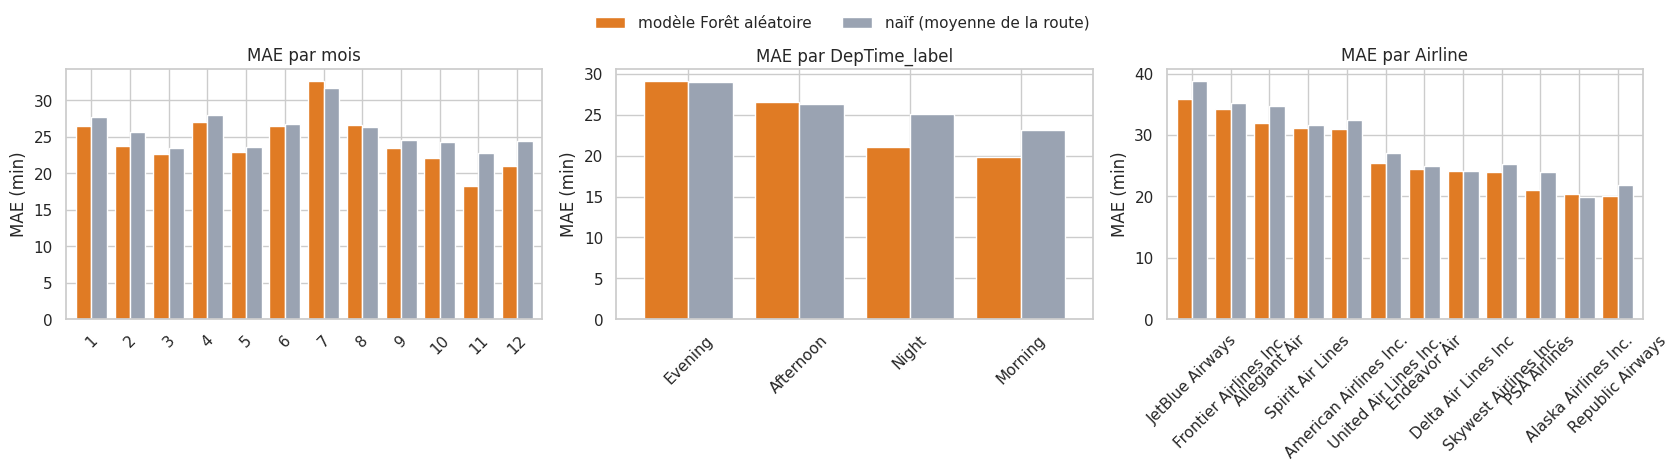

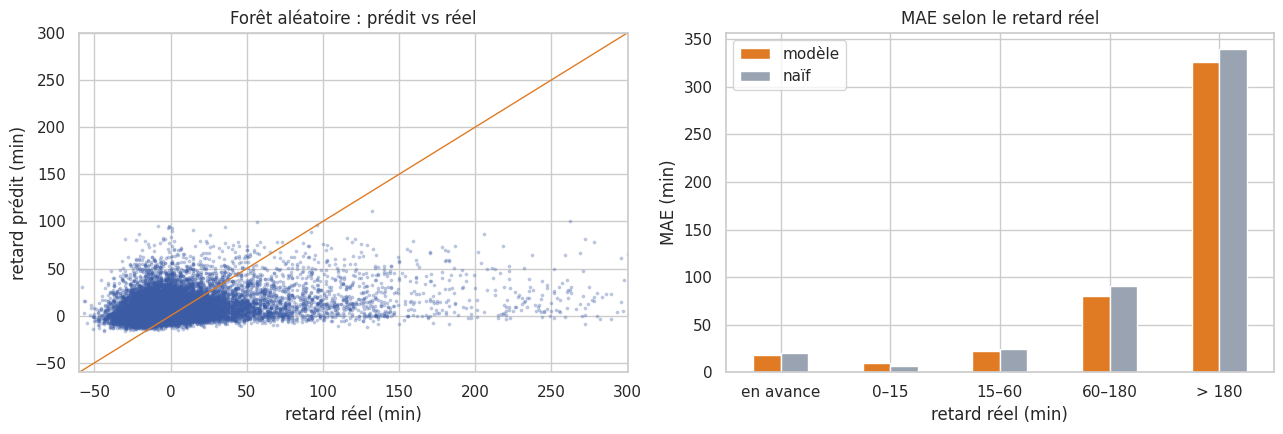

Lecture : le modèle se trompe surtout sur les gros retards, rares et souvent imprévisibles (pannes, orages).


In [33]:
p_best, p_naif = predictions[MEILLEUR], predictions["Naïf – moyenne de la route"]
err = val[[c for c in ["mois", trouver("DepTime_label") or "tranche", trouver("Airline")] if c in val]].copy()
err["erreur modèle"], err["erreur naïf"] = np.abs(y_va.values - p_best), np.abs(y_va.values - p_naif)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, col in zip(ax, err.columns[:3]):
    g = err.groupby(col)[["erreur modèle", "erreur naïf"]].mean()
    if col != "mois":
        g = g.sort_values("erreur modèle", ascending=False).head(12)
    g.plot.bar(ax=a, color=[ORANGE, GRIS], width=.8, legend=False)
    a.set(title=f"MAE par {col}", ylabel="MAE (min)", xlabel=""); a.tick_params(axis="x", rotation=45)
fig.legend(["modèle " + MEILLEUR, "naïf (moyenne de la route)"], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.06))
sauver("02_erreurs_par_segment")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
idx = np.random.default_rng(GRAINE).choice(len(y_va), min(20_000, len(y_va)), replace=False)
ax[0].scatter(y_va.values[idx], p_best[idx], s=3, alpha=.25, color=BLEU)
ax[0].plot([-60, 300], [-60, 300], color=ORANGE, lw=1)
ax[0].set(xlim=(-60, 300), ylim=(-60, 300), title=f"{MEILLEUR} : prédit vs réel", xlabel="retard réel (min)", ylabel="retard prédit (min)")
classes = pd.cut(y_va, [-np.inf, 0, 15, 60, 180, np.inf], labels=["en avance", "0–15", "15–60", "60–180", "> 180"])
pd.DataFrame({"modèle": np.abs(y_va.values - p_best), "naïf": np.abs(y_va.values - p_naif)}).groupby(classes.values).mean() \
  .plot.bar(ax=ax[1], color=[ORANGE, GRIS])
ax[1].set(title="MAE selon le retard réel", xlabel="retard réel (min)", ylabel="MAE (min)"); ax[1].tick_params(axis="x", rotation=0)
sauver("03_predit_vs_reel")
print("Lecture : le modèle se trompe surtout sur les gros retards, rares et souvent imprévisibles (pannes, orages).")

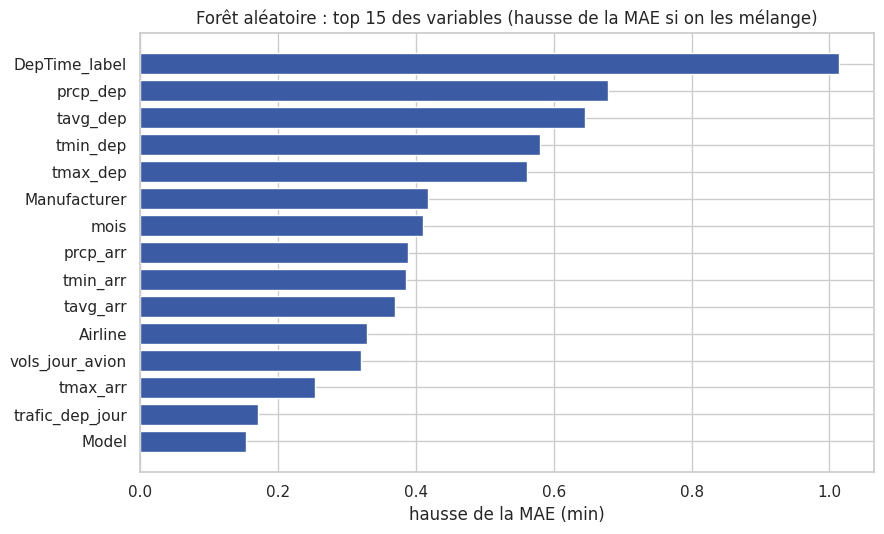

In [34]:
# Variables les plus importantes (importance par permutation sur 20 000 vols de validation)
sous = X_va.sample(min(20_000, len(X_va)), random_state=GRAINE)
imp = permutation_importance(entraines[MEILLEUR], sous, y_va.loc[sous.index], n_repeats=3,
                             scoring="neg_mean_absolute_error", random_state=GRAINE, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=sous.columns).sort_values(ascending=False).head(15)[::-1]
plt.figure(figsize=(9, 5.5)); plt.barh(imp.index, imp.values, color=BLEU)
plt.title(f"{MEILLEUR} : top 15 des variables (hausse de la MAE si on les mélange)"); plt.xlabel("hausse de la MAE (min)")
sauver("04_importance_variables")

## 22. Journal des expériences

Chaque exécution ajoute ses résultats à `journal_experiences.csv` (date, modèle, paramètres, métriques). Ce journal servira au **suivi des expérimentations** pendant l'optimisation.

In [35]:
horodatage = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
journal = res.copy()
journal.insert(0, "date", horodatage)
journal["paramètres"] = [json.dumps(modeles[m].named_steps["mod"].get_params(), default=str)[:500] if m in modeles else ""
                         for m in journal["modèle"]]
journal["vols entraînement"], journal["vols validation"] = len(X_tr), len(X_va)
journal.to_csv("journal_experiences.csv", mode="a", index=False, encoding="utf-8-sig",
               header=not os.path.exists("journal_experiences.csv"))

b = res.set_index("modèle").loc[MEILLEUR]
print("=== Valeurs actuelles pour le contrat d'optimisation (validation) ===")
print(f"Meilleur modèle                     : {MEILLEUR}")
print(f"MAE                                 : {b['MAE (min)']:.2f} min  (naïf route : {MAE_NAIF:.2f} min, gain {b['gain MAE vs naïf route']})")
print(f"RMSE                                : {b['RMSE (min)']:.2f} min")
print(f"R²                                  : {b['R²']:.3f}")
print(f"Capture des retards ≥ {SEUIL_GROS_RETARD} min (top {PART_SIGNALEE:.0%}) : {b['capture gros retards (%)']:.1f} %  (hasard : {PART_SIGNALEE * 100:.0f} %)")
print(f"Prédictions à ±15 min               : {b['prédictions à ±15 min (%)']:.1f} %")
print(f"Prédiction pour 1 000 vols          : {b['prédiction / 1 000 vols (ms)']:.1f} ms")

import shutil
shutil.make_archive("figures_jalon2", "zip", "figures_jalon2")
try:
    from google.colab import files
    for f in ["journal_experiences.csv", "figures_jalon2.zip"]:
        files.download(f)
except Exception:
    print("\nFichiers créés : journal_experiences.csv, figures_jalon2.zip")

=== Valeurs actuelles pour le contrat d'optimisation (validation) ===
Meilleur modèle                     : Forêt aléatoire
MAE                                 : 24.36 min  (naïf route : 25.70 min, gain 5.2 %)
RMSE                                : 53.50 min
R²                                  : 0.063
Capture des retards ≥ 60 min (top 10%) : 32.5 %  (hasard : 10 %)
Prédictions à ±15 min               : 48.1 %
Prédiction pour 1 000 vols          : 12.2 ms


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23. Suivi des expériences avec MLflow (DagsHub)

In [36]:
# ===== PARAMÈTRES MLFLOW =====
DAGSHUB_UTILISATEUR = "gnichimariem1-cell"
DAGSHUB_DEPOT = "predivol"
NOM_EXPERIENCE = "predivol-modeles-de-base"

import subprocess, sys, os
from getpass import getpass
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlflow"], check=True)
import mlflow

# Connexion directe au serveur MLflow de DagsHub (le jeton n'est pas écrit dans le notebook)
os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_UTILISATEUR
os.environ["MLFLOW_TRACKING_PASSWORD"] = getpass("Collez votre jeton DagsHub puis Entrée : ")
mlflow.set_tracking_uri(f"https://dagshub.com/{DAGSHUB_UTILISATEUR}/{DAGSHUB_DEPOT}.mlflow")
mlflow.set_experiment(NOM_EXPERIENCE)

for _, ligne in res.iterrows():
    nom = ligne["modèle"]
    with mlflow.start_run(run_name=nom):
        mlflow.set_tags({"projet": "PrédiVol", "type": "naïf" if nom.startswith("Naïf") else "modèle",
                         "meilleur": str(nom == MEILLEUR)})
        if nom in modeles:
            params = modeles[nom].named_steps["mod"].get_params()
            mlflow.log_params({k: str(v)[:250] for k, v in params.items()})
        mlflow.log_params({"taille_echantillon": TAILLE_ECHANTILLON, "separation": "70/15/15 par jour",
                           "vols_entrainement": len(X_tr), "vols_validation": len(X_va)})
        mesures = {"MAE_min": ligne["MAE (min)"], "RMSE_min": ligne["RMSE (min)"], "R2": ligne["R²"],
                   "capture_gros_retards_pct": ligne["capture gros retards (%)"],
                   "predictions_15min_pct": ligne["prédictions à ±15 min (%)"]}
        if not np.isnan(ligne["entraînement (s)"]):
            mesures.update({"entrainement_s": ligne["entraînement (s)"],
                            "prediction_1000_vols_ms": ligne["prédiction / 1 000 vols (ms)"]})
        mlflow.log_metrics(mesures)
        if nom == MEILLEUR:
            for f in ["figures_jalon2.zip", "journal_experiences.csv", "comparaison_metriques.csv"]:
                if os.path.exists(f):
                    mlflow.log_artifact(f)

print(f"{len(res)} expériences envoyées.")
print(f"Interface MLflow : https://dagshub.com/{DAGSHUB_UTILISATEUR}/{DAGSHUB_DEPOT}.mlflow")

Collez votre jeton DagsHub puis Entrée : ··········
🏃 View run Naïf – moyenne globale at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0/runs/11910c7618b04a1e81b0b58a36572c07
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0
🏃 View run Naïf – moyenne de la route at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0/runs/5a23a7104cb045db875d4107567d4bad
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0
🏃 View run Ridge at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0/runs/295523e1f2fa4eea91c7755ea354b2a8
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0
🏃 View run Forêt aléatoire at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0/runs/245bf415233a4447a8da45216b646b98
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0
🏃 View r

---
# Partie 3 – Optimisation des modèles


In [ ]:
# ===== PARAMÈTRES DE LA PARTIE 3 =====
TAILLE_RECHERCHE_GB = 300_000   # vols d'entraînement utilisés pour la recherche du gradient boosting
TAILLE_RECHERCHE_RF = 200_000   # idem pour la forêt aléatoire (plus lente)
N_ESSAIS_GB = 12                # nombre de combinaisons testées (recherche aléatoire)
N_ESSAIS_RF = 5
N_PLIS = 3                      # validation croisée en 3 plis, groupés par JOUR

# Cibles du contrat d'optimisation (mesurées sur la validation)
CIBLES = {"MAE (min)": 23.1, "RMSE (min)": 56.2, "capture gros retards (%)": 36.0, "prédictions à ±15 min (%)": 51.0}

from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.preprocessing import TargetEncoder
from scipy.stats import loguniform, randint, uniform
import joblib

DEBUT_PARTIE3 = time.perf_counter()
def chrono(etape):
    print(f"⏱ {etape} : {(time.perf_counter() - DEBUT_PARTIE3) / 60:.1f} min depuis le début de la partie 3")

## 24. Préparation des données améliorée : nouvelles variables

Au Jalon 1, l'aéroport de départ, l'aéroport d'arrivée et la compagnie étaient des variables **séparées**. L'analyse des erreurs (section 21) montre que le retard dépend surtout de **combinaisons** : une route, une compagnie dans un aéroport donné, un aéroport le soir. On ajoute donc :

| Nouvelle variable | Définition | Pourquoi ? |
| --- | --- | --- |
| `route` | aéroport de départ → aéroport d'arrivée | Le modèle naïf montre que la route explique déjà une partie du retard |
| `compagnie_aeroport` | compagnie × aéroport de départ | Une compagnie peut être en retard dans un seul de ses aéroports |
| `aeroport_moment` | aéroport de départ × moment de la journée | Les retards s'accumulent au fil de la journée (effet domino) |
| `charge_relative_dep` | trafic du jour ÷ trafic habituel de l'aéroport | Un jour **anormalement** chargé est plus risqué qu'un grand aéroport un jour normal |
| `meteo_difficile` | neige, pluie > 10 mm ou vent fort, au départ **ou** à l'arrivée | Résume la météo en un signal simple |

Les trois combinaisons ont des milliers de valeurs possibles (plus de 5 000 routes). Un encodage *one-hot* serait trop lourd. On utilise donc un **encodage par la cible** (`TargetEncoder`) : chaque valeur est remplacée par le retard moyen observé pour cette valeur. Le `TargetEncoder` fait ce calcul par **validation croisée interne** sur l'entraînement seulement. Il n'y a donc pas de fuite vers la validation et le test.

On mesure d'abord l'effet de ces variables **seules**, avec le gradient boosting de base, sans changer ses réglages.

In [ ]:
MOMENT = trouver("DepTime_label") or "tranche"
COMPAGNIE = trouver("Airline")

# Trafic habituel de chaque aéroport : médiane du trafic quotidien (le planning est connu à l'avance)
trafic_habituel = vols.groupby(DEP, observed=True)["trafic_dep_jour"].median()
trafic_habituel.index = trafic_habituel.index.astype(str)

def ajouter_variables(d):
    d = d.copy()
    d["route"] = d[DEP] + "→" + d[ARR]
    d["compagnie_aeroport"] = d[COMPAGNIE] + "|" + d[DEP]
    d["aeroport_moment"] = d[DEP] + "|" + d[MOMENT].astype(str)
    d["charge_relative_dep"] = d["trafic_dep_jour"] / d[DEP].map(trafic_habituel).astype(float)
    meteo = np.zeros(len(d), bool)
    for cote in ["dep", "arr"]:
        for col, seuil in [(f"snow_{cote}", 0), (f"prcp_{cote}", 10), (f"wspd_{cote}", 30)]:
            if col in d:
                meteo |= d[col].fillna(0).to_numpy() > seuil
    d["meteo_difficile"] = meteo.astype(int)
    return d

train, val, test = ajouter_variables(train), ajouter_variables(val), ajouter_variables(test)
TE = ["route", "compagnie_aeroport", "aeroport_moment"]
NUM2 = NUM + ["charge_relative_dep", "meteo_difficile"]
VARS2 = CAT + TE + NUM2
X_tr2, X_va2 = train[VARS2], val[VARS2]
X_te, y_te = test[VARS2], test[CIBLE].astype(float)
print(f"Variables : {len(CAT) + len(NUM)} au Jalon 1 → {len(VARS2)} maintenant (+{len(VARS2) - len(CAT) - len(NUM)})")
print(f"Routes distinctes : {train['route'].nunique():,} | compagnie × aéroport : {train['compagnie_aeroport'].nunique():,}")
print(f"Vols avec météo difficile : {train['meteo_difficile'].mean() * 100:.1f} %")

def prep_arbres_v2(imputer):
    # Même prétraitement qu'en partie 2, plus l'encodage par la cible des combinaisons
    cat = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan,
                         max_categories=250, dtype=float)
    etapes_cat = [("ord", cat)] + ([("imp", SimpleImputer(strategy="constant", fill_value=-1))] if imputer else [])
    num = Pipeline([("imp", SimpleImputer(strategy="median"))]) if imputer else "passthrough"
    return ColumnTransformer([("cat", Pipeline(etapes_cat), CAT),
                              ("te", TargetEncoder(target_type="continuous", random_state=GRAINE), TE),
                              ("num", num, NUM2)])

Variables : 30 au Jalon 1 → 35 maintenant (+5)
Routes distinctes : 6,403 | compagnie × aéroport : 1,710
Vols avec météo difficile : 19.4 %


In [ ]:
# Effet des nouvelles variables seules : gradient boosting avec EXACTEMENT les réglages de la partie 2
params_gb_base = modeles["Gradient boosting"].named_steps["mod"].get_params()
gb_vars = Pipeline([("prep", prep_arbres_v2(False)), ("mod", HistGradientBoostingRegressor(**params_gb_base))])
t0 = time.perf_counter(); gb_vars.fit(X_tr2, y_tr); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); p = gb_vars.predict(X_va2); t_pred = (time.perf_counter() - t0) / len(X_va2) * 1e6
resultats_opt = [res.set_index("modèle").loc["Naïf – moyenne de la route"].to_dict() | {"modèle": "Naïf – moyenne de la route"},
                 res.set_index("modèle").loc["Gradient boosting"].to_dict() | {"modèle": "Gradient boosting – base"},
                 mesurer("Gradient boosting – base + nouvelles variables", y_va, p, t_fit, t_pred)]
predictions["Gradient boosting – base + nouvelles variables"] = p
effet_vars = pd.DataFrame(resultats_opt)[["modèle", "MAE (min)", "RMSE (min)", "R²", "capture gros retards (%)", "prédictions à ±15 min (%)"]]
display(effet_vars.round(2))
d = effet_vars["MAE (min)"].iloc[1] - effet_vars["MAE (min)"].iloc[2]
print(f"Effet des nouvelles variables sur la MAE : {d:+.2f} min ({'amélioration' if d > 0 else 'pas d’amélioration'})")
chrono("section 24")

,modèle,MAE (min),RMSE (min),R²,capture gros retards (%),prédictions à ±15 min (%)
0,Naïf – moyenne de la route,25.70,55.27,-0.00,15.79,42.94
1,Gradient boosting – base,24.43,53.58,0.06,32.13,49.81
2,Gradient boosting – base + nouvelles variables,24.31,53.47,0.06,32.56,49.54


Effet des nouvelles variables sur la MAE : +0.12 min (amélioration)
⏱ section 24 : 3.4 min depuis le début de la partie 3


## 25. Optimisation 1 : gradient boosting (recherche aléatoire + validation croisée)

**Pourquoi une recherche aléatoire ?** Une recherche sur grille testerait toutes les combinaisons. Avec 6 hyperparamètres, c'est des centaines d'entraînements. La recherche aléatoire tire `N_ESSAIS_GB` combinaisons au hasard. À budget égal, elle trouve en général d'aussi bons réglages.

**Pourquoi une validation croisée groupée par jour ?** Les vols d'un même jour partagent la météo et les mêmes perturbations. Si un jour se retrouvait à la fois dans l'entraînement et dans l'évaluation, le score serait trop optimiste. `GroupKFold` garde chaque jour dans un seul pli, comme la séparation 70/15/15 de la section 17.

**Hyperparamètres explorés :**

| Hyperparamètre | Rôle | Valeurs essayées |
| --- | --- | --- |
| `loss` | fonction de perte | erreur au carré (base) ou **erreur absolue** (vise directement la MAE) |
| `learning_rate` | taille de chaque correction | 0,03 à 0,2 |
| `max_leaf_nodes` | complexité de chaque arbre | 31 à 255 |
| `min_samples_leaf` | nombre minimal de vols par feuille (évite le sur-apprentissage) | 20 à 400 |
| `l2_regularization` | pénalité sur les valeurs des feuilles | 0,001 à 10 |
| `max_features` | part des variables tirées à chaque découpage | 50 % à 100 % |

La recherche se fait sur un sous-échantillon de l'entraînement (`TAILLE_RECHERCHE_GB` vols), pour rester dans le temps de calcul de Colab. C'est le compromis prévu dans le contrat. Le meilleur réglage est ensuite **ré-entraîné sur tout l'entraînement** et mesuré sur la validation.

In [ ]:
def jour(d):
    return pd.to_datetime(d[DATE].astype(str)).dt.normalize()

sous_gb = train.sample(min(TAILLE_RECHERCHE_GB, len(train)), random_state=GRAINE)
espace_gb = {
    "mod__loss": ["squared_error", "absolute_error"],
    "mod__learning_rate": loguniform(0.03, 0.2),
    "mod__max_leaf_nodes": randint(31, 256),
    "mod__min_samples_leaf": randint(20, 401),
    "mod__l2_regularization": loguniform(1e-3, 10),
    "mod__max_features": uniform(0.5, 0.5),
}
pipe_gb = Pipeline([("prep", prep_arbres_v2(False)),
                    ("mod", HistGradientBoostingRegressor(categorical_features=IDX_CAT, max_iter=800, early_stopping=True,
                                                          random_state=GRAINE))])
recherche_gb = RandomizedSearchCV(pipe_gb, espace_gb, n_iter=N_ESSAIS_GB, scoring="neg_mean_absolute_error",
                                  cv=GroupKFold(n_splits=N_PLIS), random_state=GRAINE, refit=False,
                                  return_train_score=True, n_jobs=1, verbose=1)
t0 = time.perf_counter()
recherche_gb.fit(sous_gb[VARS2], sous_gb[CIBLE].astype(float), groups=jour(sous_gb))
print(f"Recherche terminée en {(time.perf_counter() - t0) / 60:.1f} min")

def tableau_recherche(r):
    t = pd.DataFrame(r.cv_results_)
    cols = [c for c in t.columns if c.startswith("param_mod__")]
    out = t[cols].rename(columns=lambda c: c.replace("param_mod__", ""))
    out["MAE CV (min)"] = -t["mean_test_score"]
    out["écart-type CV"] = t["std_test_score"]
    out["MAE entraînement"] = -t["mean_train_score"]
    out["temps / pli (s)"] = t["mean_fit_time"]
    return out.sort_values("MAE CV (min)").reset_index(drop=True)

def lisible(d):
    return {k.replace("mod__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}

essais_gb = tableau_recherche(recherche_gb)
display(essais_gb.round(3).head(8))
print("Meilleurs réglages :", lisible(recherche_gb.best_params_))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Recherche terminée en 37.8 min


,l2_regularization,learning_rate,loss,max_features,max_leaf_nodes,min_samples_leaf,MAE CV (min),écart-type CV,MAE entraînement,temps / pli (s)
0,0.050,0.045,absolute_error,0.592,221,237,22.007,0.137,19.226,87.466
1,0.680,0.031,absolute_error,0.861,188,313,22.018,0.137,19.624,129.732
2,0.063,0.063,absolute_error,0.799,78,290,22.054,0.135,20.003,51.702
3,0.001,0.168,absolute_error,0.591,162,21,22.130,0.124,19.802,16.010
4,0.002,0.182,absolute_error,0.782,39,365,22.133,0.127,20.607,15.854
5,0.061,0.036,squared_error,0.933,130,379,25.178,0.263,22.657,38.433
6,0.029,0.071,squared_error,0.809,138,74,25.218,0.152,22.678,12.876
7,8.569,0.073,squared_error,0.804,51,348,25.246,0.323,23.366,12.950


Meilleurs réglages : {'l2_regularization': 0.0502, 'learning_rate': 0.0445, 'loss': 'absolute_error', 'max_features': 0.5924, 'max_leaf_nodes': 221, 'min_samples_leaf': 237}


In [ ]:
# Ré-entraînement du meilleur réglage sur TOUT l'entraînement, puis mesure sur la validation
gb_opt = Pipeline([("prep", prep_arbres_v2(False)),
                   ("mod", HistGradientBoostingRegressor(categorical_features=IDX_CAT, max_iter=800, early_stopping=True,
                                                         random_state=GRAINE))])
gb_opt.set_params(**recherche_gb.best_params_)
t0 = time.perf_counter(); gb_opt.fit(X_tr2, y_tr); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); p = gb_opt.predict(X_va2); t_pred = (time.perf_counter() - t0) / len(X_va2) * 1e6
resultats_opt.append(mesurer("Gradient boosting – optimisé", y_va, p, t_fit, t_pred)); predictions["Gradient boosting – optimisé"] = p
print(f"Gradient boosting optimisé : MAE = {resultats_opt[-1]['MAE (min)']:.2f} min sur la validation "
      f"({gb_opt.named_steps['mod'].n_iter_} arbres, {t_fit:.0f} s)")

# Effet de la perte absolue seule : meilleur essai de chaque type de perte
print("\nMeilleure MAE en validation croisée selon la perte :")
display(essais_gb.groupby("loss")["MAE CV (min)"].min().round(3).to_frame())
chrono("section 25")

Gradient boosting optimisé : MAE = 20.95 min sur la validation (800 arbres, 279 s)

Meilleure MAE en validation croisée selon la perte :


,MAE CV (min)
loss,
absolute_error,22.007
squared_error,25.178


⏱ section 25 : 47.3 min depuis le début de la partie 3


## 26. Optimisation 2 : forêt aléatoire (recherche aléatoire + validation croisée)

La forêt aléatoire est le meilleur modèle de base. Elle est lente à entraîner, alors on fait moins d'essais (`N_ESSAIS_RF`), avec 50 arbres seulement pendant la recherche. Le réglage retenu est ensuite ré-entraîné avec 150 arbres.

| Hyperparamètre | Rôle | Valeurs essayées |
| --- | --- | --- |
| `max_depth` | profondeur maximale des arbres | 12, 16, 20, 24 |
| `min_samples_leaf` | nombre minimal de vols par feuille | 5, 10, 20, 50, 100 |
| `max_features` | part des variables tirées à chaque découpage | 30 %, 50 %, 70 % |

In [ ]:
sous_rf = train.sample(min(TAILLE_RECHERCHE_RF, len(train)), random_state=GRAINE)
espace_rf = {"mod__max_depth": [12, 16, 20, 24], "mod__min_samples_leaf": [5, 10, 20, 50, 100],
             "mod__max_features": [0.3, 0.5, 0.7]}
pipe_rf = Pipeline([("prep", prep_arbres_v2(True)),
                    ("mod", RandomForestRegressor(n_estimators=50, max_samples=min(100_000, int(len(sous_rf) * 0.6)),
                                                  n_jobs=-1, random_state=GRAINE))])
recherche_rf = RandomizedSearchCV(pipe_rf, espace_rf, n_iter=N_ESSAIS_RF, scoring="neg_mean_absolute_error",
                                  cv=GroupKFold(n_splits=N_PLIS), random_state=GRAINE, refit=False,
                                  return_train_score=True, n_jobs=1, verbose=1)
t0 = time.perf_counter()
recherche_rf.fit(sous_rf[VARS2], sous_rf[CIBLE].astype(float), groups=jour(sous_rf))
print(f"Recherche terminée en {(time.perf_counter() - t0) / 60:.1f} min")
essais_rf = tableau_recherche(recherche_rf)
display(essais_rf.round(3))
print("Meilleurs réglages :", lisible(recherche_rf.best_params_))

rf_opt = Pipeline([("prep", prep_arbres_v2(True)),
                   ("mod", RandomForestRegressor(n_estimators=150, max_samples=min(200_000, len(X_tr2)),
                                                 n_jobs=-1, random_state=GRAINE))])
rf_opt.set_params(**recherche_rf.best_params_)
t0 = time.perf_counter(); rf_opt.fit(X_tr2, y_tr); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); p = rf_opt.predict(X_va2); t_pred = (time.perf_counter() - t0) / len(X_va2) * 1e6
resultats_opt.insert(-1, res.set_index("modèle").loc["Forêt aléatoire"].to_dict() | {"modèle": "Forêt aléatoire – base"})
resultats_opt.append(mesurer("Forêt aléatoire – optimisée", y_va, p, t_fit, t_pred)); predictions["Forêt aléatoire – optimisée"] = p
print(f"Forêt aléatoire optimisée : MAE = {resultats_opt[-1]['MAE (min)']:.2f} min sur la validation ({t_fit:.0f} s)")
chrono("section 26")

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Recherche terminée en 8.5 min


,min_samples_leaf,max_features,max_depth,MAE CV (min),écart-type CV,MAE entraînement,temps / pli (s)
0,50,0.7,12,25.015,0.325,23.872,36.881
1,5,0.3,12,25.190,0.309,23.489,18.242
2,5,0.5,12,25.286,0.337,23.480,29.453
3,10,0.5,20,25.290,0.345,21.736,42.462
4,5,0.3,24,25.536,0.326,20.159,31.389


Meilleurs réglages : {'min_samples_leaf': 50, 'max_features': 0.7, 'max_depth': 12}
Forêt aléatoire optimisée : MAE = 24.26 min sur la validation (292 s)
⏱ section 26 : 60.7 min depuis le début de la partie 3


## 27. Comparaison : versions de base et versions optimisées (validation)

Le tableau compare, sur le même jeu de validation, le modèle naïf, les deux modèles de base de la partie 2 et leurs versions optimisées. Le graphique montre chaque version de base et sa version optimisée, avec la cible du contrat en pointillés.

,modèle,MAE (min),RMSE (min),R²,capture gros retards (%),prédictions à ±15 min (%),entraînement (s),prédiction / 1 000 vols (ms),gain MAE vs naïf route
0,Naïf – moyenne de la route,25.70,55.27,-0.00,15.79,42.94,NaN,NaN,0.0 %
1,Gradient boosting – base,24.43,53.58,0.06,32.13,49.81,33.23,28.34,4.9 %
2,Gradient boosting – base + nouvelles variables,24.31,53.47,0.06,32.56,49.54,51.75,30.17,5.4 %
3,Gradient boosting – optimisé,20.95,54.61,0.02,31.25,65.16,278.90,169.29,18.5 %
4,Forêt aléatoire – base,24.36,53.50,0.06,32.49,48.13,197.58,12.23,5.2 %
5,Forêt aléatoire – optimisée,24.26,53.51,0.06,32.66,48.13,291.63,12.36,5.6 %


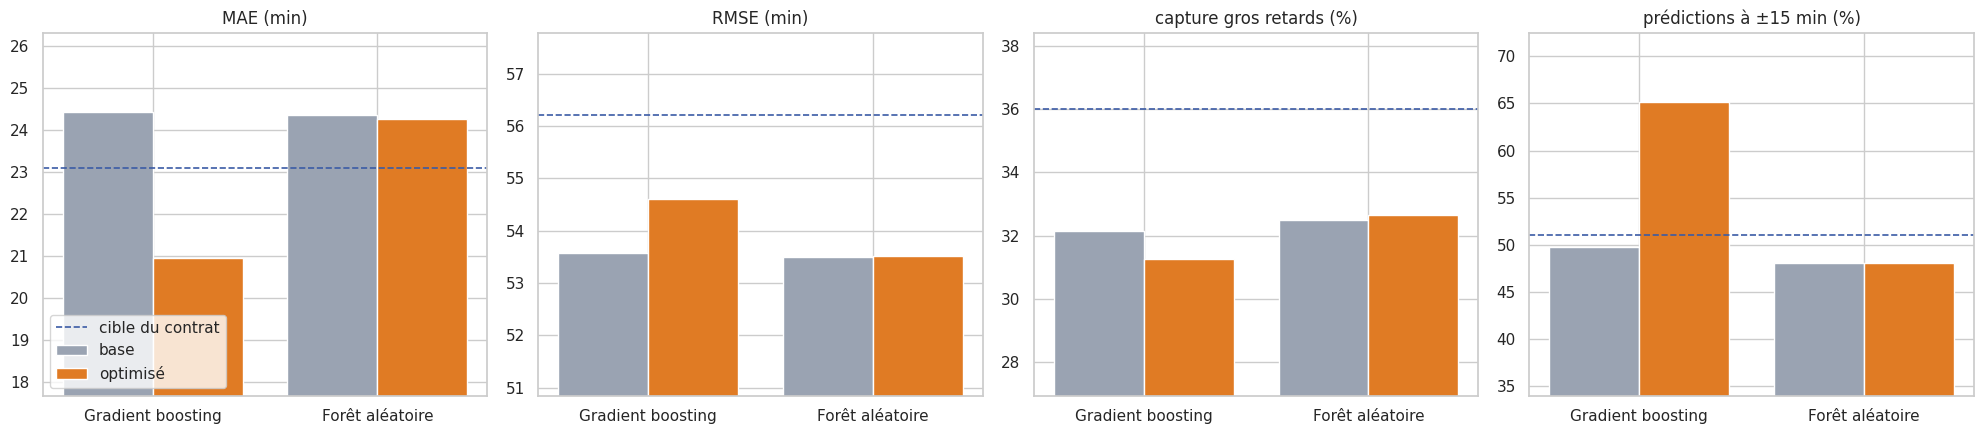

⏱ section 27 : 60.7 min depuis le début de la partie 3


In [ ]:
comp = pd.DataFrame(resultats_opt)
ordre_lignes = ["Naïf – moyenne de la route", "Gradient boosting – base", "Gradient boosting – base + nouvelles variables",
                "Gradient boosting – optimisé", "Forêt aléatoire – base", "Forêt aléatoire – optimisée"]
comp = comp.set_index("modèle").loc[ordre_lignes].reset_index()
comp["gain MAE vs naïf route"] = ((1 - comp["MAE (min)"] / MAE_NAIF) * 100).round(1).astype(str) + " %"
colonnes = ["modèle", "MAE (min)", "RMSE (min)", "R²", "capture gros retards (%)", "prédictions à ±15 min (%)",
            "entraînement (s)", "prédiction / 1 000 vols (ms)", "gain MAE vs naïf route"]
display(comp[colonnes].round(2))
comp[colonnes].to_csv("comparaison_base_optimise.csv", index=False, encoding="utf-8-sig")

# Graphique : base vs optimisé pour les 4 métriques du contrat
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
paires = [("Gradient boosting", "Gradient boosting – base", "Gradient boosting – optimisé"),
          ("Forêt aléatoire", "Forêt aléatoire – base", "Forêt aléatoire – optimisée")]
c = comp.set_index("modèle")
for a, met in zip(ax, CIBLES):
    x = np.arange(len(paires))
    a.bar(x - .2, [c.loc[b, met] for _, b, _ in paires], .4, color=GRIS, label="base")
    a.bar(x + .2, [c.loc[o, met] for _, _, o in paires], .4, color=ORANGE, label="optimisé")
    a.axhline(CIBLES[met], color=BLEU, ls="--", lw=1.2, label="cible du contrat")
    a.set_xticks(x, [n for n, _, _ in paires]); a.set_title(met)
    bas = min(c.loc[[b for _, b, _ in paires] + [o for _, _, o in paires], met].min(), CIBLES[met])
    haut = max(c.loc[[b for _, b, _ in paires] + [o for _, _, o in paires], met].max(), CIBLES[met])
    a.set_ylim(bas - (haut - bas) * 0.8 - 0.5, haut + (haut - bas) * 0.4 + 0.5)
ax[0].legend(loc="lower left")
sauver("05_base_vs_optimise")
chrono("section 27")

## 28. Choix du modèle final et évaluation sur le jeu de test

**Critères de choix, dans l'ordre :**
1. **Performance** : la MAE la plus basse en validation (métrique principale du contrat), sans hausse de plus de 5 % de la RMSE.
2. **Stabilité** : un écart-type faible entre les plis de la validation croisée.
3. **Contraintes du contrat** : moins de 50 ms pour prédire 1 000 vols.
4. **Interprétabilité** : l'importance des variables reste lisible pour les planificateurs.

Le jeu de **test** n'a jamais servi, ni pour entraîner ni pour choisir. Il donne donc une estimation honnête de la performance attendue sur de nouveaux vols.

In [ ]:
optimises = {"Gradient boosting – optimisé": (gb_opt, essais_gb), "Forêt aléatoire – optimisée": (rf_opt, essais_rf)}
MAE_BASE = res.set_index("modèle").loc[MEILLEUR, "MAE (min)"]
RMSE_BASE = res.set_index("modèle").loc[MEILLEUR, "RMSE (min)"]
choix_final = []
for nom, (pipe, essais) in optimises.items():
    l = c.loc[nom]
    gain = (1 - l["MAE (min)"] / MAE_BASE) * 100
    choix_final.append({"modèle": nom, "MAE validation (min)": l["MAE (min)"],
                        "gain MAE vs base (%)": gain,
                        "RMSE validation (min)": l["RMSE (min)"],
                        "RMSE ≤ 5 % au-dessus de la base": l["RMSE (min)"] <= RMSE_BASE * 1.05,
                        "écart-type MAE en CV (min)": essais.loc[0, "écart-type CV"],
                        "prédiction / 1 000 vols (ms)": l["prédiction / 1 000 vols (ms)"],
                        # Contrat : < 50 ms, OU modèle plus lourd accepté s'il améliore la MAE d'au moins 2 %
                        "temps acceptable (contrat)": (l["prédiction / 1 000 vols (ms)"] < 50) or (gain >= 2)})
choix_final = pd.DataFrame(choix_final)
admissibles = choix_final[choix_final["RMSE ≤ 5 % au-dessus de la base"] & choix_final["temps acceptable (contrat)"]]
FINAL = (admissibles if len(admissibles) else choix_final).sort_values("MAE validation (min)").iloc[0]["modèle"]
modele_final = optimises[FINAL][0]
display(choix_final.round(3))
print(f"Modèle final retenu : {FINAL}")

# Évaluation unique sur le TEST : modèle final et modèle naïf de la route
p_te = modele_final.predict(X_te)
p_naif_te = route(test).map(moy_route).fillna(test[DEP].map(moy_dep)).fillna(y_tr.mean()).to_numpy(float)
test_res = pd.DataFrame([mesurer("Naïf – moyenne de la route (test)", y_te, p_naif_te),
                         mesurer(f"{FINAL} (test)", y_te, p_te)])
cols_t = ["modèle", "MAE (min)", "RMSE (min)", "R²", "capture gros retards (%)", "prédictions à ±15 min (%)"]
display(test_res[cols_t].round(2))
MAE_TEST, MAE_NAIF_TEST = test_res["MAE (min)"].iloc[1], test_res["MAE (min)"].iloc[0]
print(f"Gain sur le test par rapport au naïf de la route : {(1 - MAE_TEST / MAE_NAIF_TEST) * 100:.1f} %")
print(f"Écart validation → test : {MAE_TEST - c.loc[FINAL, 'MAE (min)']:+.2f} min (petit écart = modèle stable)")

,modèle,MAE validation (min),gain MAE vs base (%),RMSE validation (min),RMSE ≤ 5 % au-dessus de la base,écart-type MAE en CV (min),prédiction / 1 000 vols (ms),temps acceptable (contrat)
0,Gradient boosting – optimisé,20.952,13.988,54.611,True,0.137,169.291,True
1,Forêt aléatoire – optimisée,24.256,0.424,53.507,True,0.325,12.363,True


Modèle final retenu : Gradient boosting – optimisé


,modèle,MAE (min),RMSE (min),R²,capture gros retards (%),prédictions à ±15 min (%)
0,Naïf – moyenne de la route (test),26.04,56.76,0.00,15.67,43.24
1,Gradient boosting – optimisé (test),21.48,56.33,0.02,31.93,65.20


Gain sur le test par rapport au naïf de la route : 17.5 %
Écart validation → test : +0.53 min (petit écart = modèle stable)


### 28 bis. Vérification des cibles du contrat et intervalle de prédiction

Le contrat prévoyait aussi une **prédiction par intervalle** : au lieu d'un seul chiffre, on donne une fourchette où le retard a 80 % de chances de tomber. Pour cela, on entraîne deux modèles de **régression quantile** (quantiles 10 % et 90 %) avec les réglages du gradient boosting optimisé.

In [ ]:
# Cibles du contrat : base (partie 2) → modèle final (validation)
b, f = res.set_index("modèle").loc[MEILLEUR], c.loc[FINAL]
sens = {"MAE (min)": "≤", "RMSE (min)": "≤", "capture gros retards (%)": "≥", "prédictions à ±15 min (%)": "≥"}
bilan = pd.DataFrame([{"métrique": m, "base (Jalon 2, partie 2)": round(b[m], 2), "cible": f"{sens[m]} {CIBLES[m]}",
                       "modèle final": round(f[m], 2),
                       "cible atteinte": "oui" if (f[m] <= CIBLES[m] if sens[m] == "≤" else f[m] >= CIBLES[m]) else "non",
                       "évolution": f"{f[m] - b[m]:+.2f}"} for m in CIBLES])
display(bilan)
bilan.to_csv("bilan_contrat.csv", index=False, encoding="utf-8-sig")

# Intervalle 10 %–90 % (régression quantile)
reglages = {k.replace("mod__", ""): v for k, v in recherche_gb.best_params_.items() if k != "mod__loss"}
bornes = {}
for q in [0.1, 0.9]:
    mq = Pipeline([("prep", prep_arbres_v2(False)),
                   ("mod", HistGradientBoostingRegressor(loss="quantile", quantile=q, categorical_features=IDX_CAT,
                                                         max_iter=800, early_stopping=True, random_state=GRAINE, **reglages))])
    mq.fit(X_tr2, y_tr); bornes[q] = mq.predict(X_te)
dedans = (y_te.values >= bornes[0.1]) & (y_te.values <= bornes[0.9])
LARGEUR = np.median(bornes[0.9] - bornes[0.1])
print(f"Intervalle 10–90 % (test) : {dedans.mean() * 100:.1f} % des vols dedans (attendu ≈ 80 %), "
      f"largeur médiane {LARGEUR:.0f} min (modèle naïf par route, Jalon 1 : 59 min)")
chrono("section 28")

,métrique,"base (Jalon 2, partie 2)",cible,modèle final,cible atteinte,évolution
0,MAE (min),24.36,≤ 23.1,20.95,oui,-3.41
1,RMSE (min),53.50,≤ 56.2,54.61,oui,+1.11
2,capture gros retards (%),32.49,≥ 36.0,31.25,non,-1.24
3,prédictions à ±15 min (%),48.13,≥ 51.0,65.16,oui,+17.03


Intervalle 10–90 % (test) : 76.5 % des vols dedans (attendu ≈ 80 %), largeur médiane 48 min (modèle naïf par route, Jalon 1 : 59 min)
⏱ section 28 : 74.3 min depuis le début de la partie 3


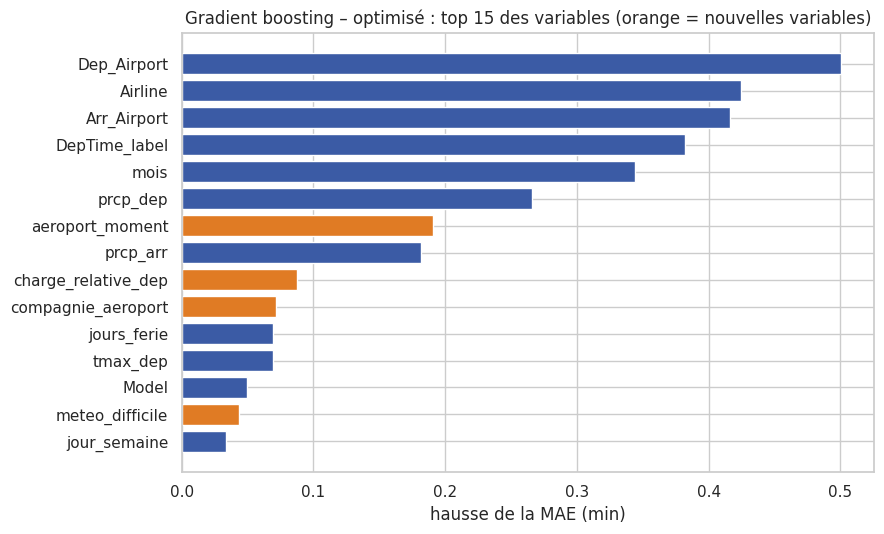

Top 5 : Dep_Airport, Airline, Arr_Airport, DepTime_label, mois
Modèle enregistré : modele_final.joblib (11 Mo)


In [ ]:
# Variables les plus importantes du modèle final (permutation sur 10 000 vols de test)
sous = X_te.sample(min(10_000, len(X_te)), random_state=GRAINE)
imp = permutation_importance(modele_final, sous, y_te.loc[sous.index], n_repeats=3,
                             scoring="neg_mean_absolute_error", random_state=GRAINE, n_jobs=1)
imp = pd.Series(imp.importances_mean, index=sous.columns).sort_values(ascending=False)
couleurs = [ORANGE if v in TE + ["charge_relative_dep", "meteo_difficile"] else BLEU for v in imp.head(15).index[::-1]]
plt.figure(figsize=(9, 5.5)); plt.barh(imp.head(15).index[::-1], imp.head(15).values[::-1], color=couleurs)
plt.title(f"{FINAL} : top 15 des variables (orange = nouvelles variables)"); plt.xlabel("hausse de la MAE (min)")
sauver("06_importance_modele_final")
print("Top 5 :", ", ".join(imp.head(5).index))

# Sauvegarde du modèle final (servira au déploiement, Jalon 3)
joblib.dump(modele_final, "modele_final.joblib", compress=3)
print(f"Modèle enregistré : modele_final.joblib ({os.path.getsize('modele_final.joblib') / 1e6:.0f} Mo)")

## 29. Journal des expériences et suivi MLflow de l'optimisation

Tous les essais de la recherche (avec leurs réglages et leur score en validation croisée) et les modèles optimisés sont ajoutés à `journal_experiences.csv`. Ils sont aussi envoyés dans une **nouvelle expérience MLflow**, `predivol-optimisation`, sur DagsHub. Si la section 23 a déjà été exécutée dans cette session, le jeton n'est pas redemandé.

In [ ]:
horodatage = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
lignes = []
for nom_mod, essais in [("Gradient boosting – essai CV", essais_gb), ("Forêt aléatoire – essai CV", essais_rf)]:
    for i, e in essais.iterrows():
        reg = {k: (v.item() if hasattr(v, "item") else v) for k, v in e.items()
               if k not in ("MAE CV (min)", "écart-type CV", "MAE entraînement", "temps / pli (s)")}
        lignes.append({"date": horodatage, "modèle": f"{nom_mod} {i + 1}", "MAE (min)": e["MAE CV (min)"],
                       "paramètres": json.dumps(reg, default=str), "évaluation": f"validation croisée {N_PLIS} plis"})
for _, l in comp.iterrows():
    if "optimis" in l["modèle"] or "nouvelles" in l["modèle"]:
        lignes.append(l.to_dict() | {"date": horodatage, "évaluation": "validation"})
lignes.append(test_res.iloc[1].to_dict() | {"date": horodatage, "évaluation": "test (modèle final)"})
pd.DataFrame(lignes).to_csv("journal_experiences.csv", mode="a", index=False, encoding="utf-8-sig",
                            header=not os.path.exists("journal_experiences.csv"))
essais_gb.to_csv("essais_gradient_boosting.csv", index=False, encoding="utf-8-sig")
essais_rf.to_csv("essais_foret_aleatoire.csv", index=False, encoding="utf-8-sig")
print(f"{len(lignes)} lignes ajoutées à journal_experiences.csv")

ENVOYER_MLFLOW = True
if ENVOYER_MLFLOW:
    try:
        import mlflow, shutil
        from getpass import getpass
        if not os.environ.get("MLFLOW_TRACKING_PASSWORD"):
            os.environ["MLFLOW_TRACKING_USERNAME"] = "gnichimariem1-cell"
            os.environ["MLFLOW_TRACKING_PASSWORD"] = getpass("Collez votre jeton DagsHub puis Entrée : ")
        utilisateur = os.environ["MLFLOW_TRACKING_USERNAME"]
        mlflow.set_tracking_uri(f"https://dagshub.com/{utilisateur}/predivol.mlflow")
        mlflow.set_experiment("predivol-optimisation")
        for nom_mod, essais in [("Gradient boosting", essais_gb), ("Forêt aléatoire", essais_rf)]:
            for i, e in essais.iterrows():
                with mlflow.start_run(run_name=f"{nom_mod} – essai {i + 1}"):
                    mlflow.set_tags({"projet": "PrédiVol", "type": "essai de recherche", "modèle": nom_mod})
                    mlflow.log_params({k: str(v) for k, v in e.items() if k not in ("MAE CV (min)", "écart-type CV", "MAE entraînement", "temps / pli (s)")})
                    mlflow.log_metrics({"MAE_CV_min": e["MAE CV (min)"], "ecart_type_CV": e["écart-type CV"],
                                        "MAE_entrainement_min": e["MAE entraînement"]})
        for nom, pipe in [("Gradient boosting – optimisé", gb_opt), ("Forêt aléatoire – optimisée", rf_opt)]:
            l = c.loc[nom]
            with mlflow.start_run(run_name=nom):
                mlflow.set_tags({"projet": "PrédiVol", "type": "modèle optimisé", "final": str(nom == FINAL)})
                mlflow.log_params({k: str(v)[:250] for k, v in pipe.named_steps["mod"].get_params().items()})
                mlflow.log_params({"variables": len(VARS2), "nouvelles_variables": ", ".join(TE + ["charge_relative_dep", "meteo_difficile"])})
                mesures = {"MAE_min": l["MAE (min)"], "RMSE_min": l["RMSE (min)"], "R2": l["R²"],
                           "capture_gros_retards_pct": l["capture gros retards (%)"],
                           "predictions_15min_pct": l["prédictions à ±15 min (%)"]}
                if nom == FINAL:
                    t = test_res.iloc[1]
                    mesures.update({"test_MAE_min": t["MAE (min)"], "test_RMSE_min": t["RMSE (min)"],
                                    "test_capture_gros_retards_pct": t["capture gros retards (%)"],
                                    "test_couverture_intervalle_pct": dedans.mean() * 100})
                    shutil.make_archive("figures_jalon2", "zip", "figures_jalon2")
                    for fch in ["comparaison_base_optimise.csv", "bilan_contrat.csv", "essais_gradient_boosting.csv",
                                "essais_foret_aleatoire.csv", "figures_jalon2.zip"]:
                        mlflow.log_artifact(fch)
                mlflow.log_metrics(mesures)
        print(f"Optimisation envoyée dans MLflow : https://dagshub.com/{utilisateur}/predivol.mlflow (expérience predivol-optimisation)")
    except Exception as e:
        print("MLflow non disponible (le reste du notebook est valide) :", str(e)[:300])

21 lignes ajoutées à journal_experiences.csv
Collez votre jeton DagsHub puis Entrée : ··········


2026/11/11 18:24:59 INFO mlflow.tracking.fluent: Experiment with name 'predivol-optimisation' does not exist. Creating a new experiment.


🏃 View run Gradient boosting – essai 1 at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/1/runs/e714583322d7410188f7600861129ca6
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/1
🏃 View run Gradient boosting – essai 2 at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/1/runs/f3a6f5912fc7446cb1374056007b306a
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/1
🏃 View run Gradient boosting – essai 3 at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/1/runs/0a46d1dc475f48f5ae9473d248c31d5a
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/1
🏃 View run Gradient boosting – essai 4 at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/1/runs/35e78fcc7c0f4c0fbd5de688d17fc8c3
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/1
🏃 View run Gradient 

In [ ]:

print("=== RÉSUMÉ PARTIE 3 ===")
print(f"Effet des nouvelles variables (GB, mêmes réglages) : MAE {c.loc['Gradient boosting – base', 'MAE (min)']:.2f} → {c.loc['Gradient boosting – base + nouvelles variables', 'MAE (min)']:.2f} min")
print("GB – meilleurs réglages :", lisible(recherche_gb.best_params_), f"| MAE CV {essais_gb.loc[0, 'MAE CV (min)']:.2f} ± {essais_gb.loc[0, 'écart-type CV']:.2f}")
print("RF – meilleurs réglages :", lisible(recherche_rf.best_params_), f"| MAE CV {essais_rf.loc[0, 'MAE CV (min)']:.2f} ± {essais_rf.loc[0, 'écart-type CV']:.2f}")
print("Meilleure MAE CV par perte (GB) :", essais_gb.groupby("loss")["MAE CV (min)"].min().round(2).to_dict())
print(f"Modèle final : {FINAL}")
print(f"Intervalle 10–90 % (test) : couverture {dedans.mean() * 100:.1f} %, largeur médiane {LARGEUR:.0f} min")
print("Top 5 variables :", ", ".join(imp.head(5).index))
print(f"Temps total partie 3 : {(time.perf_counter() - DEBUT_PARTIE3) / 60:.1f} min")
print("\nEssais du gradient boosting :")
print(essais_gb.round(3).to_string())

try:
    from google.colab import files
    shutil.make_archive("figures_jalon2", "zip", "figures_jalon2")
    for fch in ["journal_experiences.csv", "comparaison_base_optimise.csv", "bilan_contrat.csv", "figures_jalon2.zip"]:
        files.download(fch)
except Exception:
    pass

=== RÉSUMÉ PARTIE 3 ===
Effet des nouvelles variables (GB, mêmes réglages) : MAE 24.43 → 24.31 min
GB – meilleurs réglages : {'l2_regularization': 0.0502, 'learning_rate': 0.0445, 'loss': 'absolute_error', 'max_features': 0.5924, 'max_leaf_nodes': 221, 'min_samples_leaf': 237} | MAE CV 22.01 ± 0.14
RF – meilleurs réglages : {'min_samples_leaf': 50, 'max_features': 0.7, 'max_depth': 12} | MAE CV 25.02 ± 0.32
Meilleure MAE CV par perte (GB) : {'absolute_error': 22.01, 'squared_error': 25.18}
Modèle final : Gradient boosting – optimisé
Intervalle 10–90 % (test) : couverture 76.5 %, largeur médiane 48 min
Top 5 variables : Dep_Airport, Airline, Arr_Airport, DepTime_label, mois
Temps total partie 3 : 189.8 min

Essais du gradient boosting :
    l2_regularization  learning_rate            loss  max_features  max_leaf_nodes  min_samples_leaf  MAE CV (min)  écart-type CV  MAE entraînement  temps / pli (s)
0               0.050          0.045  absolute_error         0.592             221       

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Partie 4 – Déploiement (UA3)

## 30. Ré-entraînement du modèle final

On ne relance pas les 3 heures d'optimisation : on reprend directement les **meilleurs réglages** trouvés à la section 25 (gradient boosting, perte absolue) et les 5 variables de la section 24. Le modèle est entraîné sur tout l'entraînement, puis vérifié sur la validation et le test.

On entraîne aussi deux modèles de **régression quantile** (10 % et 90 %) pour donner une fourchette de retard. Durée : environ 15 minutes.

In [37]:
from sklearn.preprocessing import TargetEncoder
import joblib, time

AVEC_INTERVALLE = True   # False = seulement le retard prévu (plus rapide)

# Meilleurs réglages trouvés par la recherche aléatoire (section 25)
REGLAGES_FINAUX = dict(loss="absolute_error", learning_rate=0.0445, max_leaf_nodes=221, min_samples_leaf=237,
                       l2_regularization=0.0502, max_features=0.5924, max_iter=800)

COMPAGNIE, MOMENT = trouver("Airline"), trouver("DepTime_label") or "tranche"
TE = ["route", "compagnie_aeroport", "aeroport_moment"]
NUM2 = NUM + ["charge_relative_dep", "meteo_difficile"]
VARIABLES_ENTREE = CAT + NUM            # ce que le modèle sérialisé recevra
VARIABLES_MODELE = CAT + TE + NUM2      # ce que le pipeline utilise après ajout des variables

# Trafic habituel de chaque aéroport (médiane du trafic quotidien) : nécessaire pour charge_relative_dep
trafic_habituel = vols.groupby(DEP, observed=True)["trafic_dep_jour"].median()
TRAFIC_HABITUEL = {str(k): float(v) for k, v in trafic_habituel.items()}

def ajouter_variables(d, trafic=TRAFIC_HABITUEL, dep=DEP, arr=ARR, compagnie=COMPAGNIE, moment=MOMENT):
    # Les 5 variables de la section 24 (toutes connues avant le départ)
    d = d.copy()
    d["route"] = d[dep].astype(str) + "→" + d[arr].astype(str)
    d["compagnie_aeroport"] = d[compagnie].astype(str) + "|" + d[dep].astype(str)
    d["aeroport_moment"] = d[dep].astype(str) + "|" + d[moment].astype(str)
    d["charge_relative_dep"] = d["trafic_dep_jour"] / d[dep].astype(str).map(trafic).astype(float)
    meteo = np.zeros(len(d), bool)
    for cote in ["dep", "arr"]:
        for col, seuil in [(f"snow_{cote}", 0), (f"prcp_{cote}", 10), (f"wspd_{cote}", 30)]:
            if col in d:
                meteo |= pd.to_numeric(d[col], errors="coerce").fillna(0).to_numpy() > seuil
    d["meteo_difficile"] = meteo.astype(int)
    return d

def pipeline_final(**reglages):
    cat = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan,
                         max_categories=250, dtype=float)
    prep = ColumnTransformer([("cat", cat, CAT),
                              ("te", TargetEncoder(target_type="continuous", random_state=GRAINE), TE),
                              ("num", "passthrough", NUM2)])
    return Pipeline([("prep", prep), ("mod", HistGradientBoostingRegressor(
        categorical_features=list(range(len(CAT))), early_stopping=True, random_state=GRAINE, **reglages))])

X_tr_f, X_va_f, X_te_f = (ajouter_variables(d[VARIABLES_ENTREE])[VARIABLES_MODELE] for d in (train, val, test))
y_te = test[CIBLE].astype(float)

t0 = time.perf_counter()
modele_final = pipeline_final(**REGLAGES_FINAUX).fit(X_tr_f, y_tr)
print(f"Modèle final entraîné en {time.perf_counter() - t0:.0f} s ({modele_final.named_steps['mod'].n_iter_} arbres)")

quantiles = {}
if AVEC_INTERVALLE:
    reglages_q = {k: v for k, v in REGLAGES_FINAUX.items() if k != "loss"}
    for q in [0.1, 0.9]:
        quantiles[q] = pipeline_final(loss="quantile", quantile=q, **reglages_q).fit(X_tr_f, y_tr)
        print(f"Modèle quantile {q:.0%} entraîné")

controle = pd.DataFrame([mesurer("Modèle final (validation)", y_va, modele_final.predict(X_va_f)),
                         mesurer("Modèle final (test)", y_te, modele_final.predict(X_te_f))])
display(controle[["modèle", "MAE (min)", "RMSE (min)", "capture gros retards (%)", "prédictions à ±15 min (%)"]].round(2))
print("Attendu (Jalon 2) : MAE ≈ 20,95 min en validation et ≈ 21,48 min sur le test")

Modèle final entraîné en 329 s (800 arbres)
Modèle quantile 10% entraîné
Modèle quantile 90% entraîné


,modèle,MAE (min),RMSE (min),capture gros retards (%),prédictions à ±15 min (%)
0,Modèle final (validation),20.97,54.62,31.45,65.15
1,Modèle final (test),21.48,56.31,31.53,65.31


Attendu (Jalon 2) : MAE ≈ 20,95 min en validation et ≈ 21,48 min sur le test


## 31. Sérialisation du modèle avec MLflow

**Sérialiser**, c'est enregistrer le modèle entraîné dans un format qu'on peut recharger plus tard, ailleurs (dans l'API, dans un conteneur Docker), sans le ré-entraîner.

On utilise le format **`mlflow.pyfunc`** :
- une classe `ModelePrediVol` regroupe tout ce qu'il faut pour prédire : l'ajout des 5 variables, le pipeline final et les deux modèles quantiles. L'API n'aura qu'à envoyer les informations d'un vol ;
- une **signature** décrit les colonnes attendues en entrée et en sortie ;
- les **versions** des bibliothèques (scikit-learn, pandas…) sont notées, pour recréer le même environnement dans Docker ;
- le modèle est **enregistré dans le registre de modèles** de DagsHub (`predivol-retard-arrivee`), avec un numéro de version, et aussi sauvegardé dans un dossier `predivol_modele` à mettre dans `models/` du dépôt.

In [38]:
import mlflow, mlflow.pyfunc, cloudpickle, sklearn, shutil
from mlflow.models import infer_signature

NOM_MODELE_REGISTRE = "predivol-retard-arrivee"

class ModelePrediVol(mlflow.pyfunc.PythonModel):
    # Reçoit les informations brutes d'un ou plusieurs vols et renvoie le retard prévu (et la fourchette).

    def __init__(self, entree, ajouter_variables, variables_modele):
        self.entree, self.ajouter_variables, self.variables_modele = entree, ajouter_variables, variables_modele

    def load_context(self, context):
        import joblib
        self.modele = joblib.load(context.artifacts["modele"])
        self.q10 = joblib.load(context.artifacts["q10"]) if "q10" in context.artifacts else None
        self.q90 = joblib.load(context.artifacts["q90"]) if "q90" in context.artifacts else None

    def predict(self, context, model_input, params=None):
        import numpy as np, pandas as pd
        d = pd.DataFrame(model_input).copy()
        for c in self.entree:                      # colonne absente (ex. météo inconnue) = valeur manquante
            if c not in d:
                d[c] = np.nan
        X = self.ajouter_variables(d[self.entree])[self.variables_modele]
        sortie = pd.DataFrame({"retard_prevu_min": self.modele.predict(X)})
        if self.q10 is not None and self.q90 is not None:
            bas, haut = self.q10.predict(X), self.q90.predict(X)
            sortie["borne_basse_min"] = np.minimum(bas, sortie["retard_prevu_min"])
            sortie["borne_haute_min"] = np.maximum(haut, sortie["retard_prevu_min"])
        return sortie.round(1)

# 1. Fichiers du modèle (artefacts)
os.makedirs("artefacts", exist_ok=True)
artefacts = {"modele": "artefacts/modele_final.joblib"}
joblib.dump(modele_final, artefacts["modele"], compress=3)
for q, nom in [(0.1, "q10"), (0.9, "q90")]:
    if q in quantiles:
        artefacts[nom] = f"artefacts/modele_{nom}.joblib"
        joblib.dump(quantiles[q], artefacts[nom], compress=3)

# 2. Le modèle « pyfunc », sa signature, un exemple d'entrée et les versions des bibliothèques
modele_pyfunc = ModelePrediVol(VARIABLES_ENTREE, ajouter_variables, VARIABLES_MODELE)
exemple = val[VARIABLES_ENTREE].head(3).reset_index(drop=True)
for c in NUM:
    exemple[c] = exemple[c].astype("float64")
modele_pyfunc.load_context(type("Contexte", (), {"artifacts": artefacts})())
signature = infer_signature(exemple, modele_pyfunc.predict(None, exemple))
dependances = [f"mlflow=={mlflow.__version__}", f"scikit-learn=={sklearn.__version__}", f"pandas=={pd.__version__}",
               f"numpy=={np.__version__}", f"cloudpickle=={cloudpickle.__version__}"]
description = {"modele": "Gradient boosting (perte absolue) + régression quantile 10 %/90 %",
               "mae_validation_min": round(float(controle.loc[0, "MAE (min)"]), 2),
               "mae_test_min": round(float(controle.loc[1, "MAE (min)"]), 2)}
print(signature)

# 3. Sauvegarde locale (dossier à mettre dans models/ du dépôt GitHub)
shutil.rmtree("predivol_modele", ignore_errors=True)
mlflow.pyfunc.save_model(path="predivol_modele", python_model=modele_pyfunc, artifacts=artefacts,
                         signature=signature, input_example=exemple, pip_requirements=dependances,
                         metadata=description)
print("Modèle sauvegardé dans le dossier predivol_modele/")
print("Versions à reprendre dans Docker :", dependances)

/usr/local/lib/python3.13/dist-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
2026/11/24 02:05:35 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
2026/11/24 02:05:35 INFO mlflow.pyfunc: Validating input example against model signature


inputs: 
  ['Airline': string (required), 'Dep_Airport': string (required), 'Arr_Airport': string (required), 'DepTime_label': string (required), 'Distance_type': string (required), 'Manufacturer': string (required), 'Model': string (required), 'mois': double (required), 'jour_semaine': double (required), 'Aicraft_age': double (required), 'vols_jour_avion': double (required), 'trafic_dep_jour': double (required), 'trafic_arr_jour': double (required), 'jours_ferie': double (required), 'tavg_dep': double (required), 'tmin_dep': double (required), 'tmax_dep': double (required), 'prcp_dep': double (required), 'snow_dep': double (required), 'wdir_dep': double (required), 'wspd_dep': double (required), 'pres_dep': double (required), 'tavg_arr': double (required), 'tmin_arr': double (required), 'tmax_arr': double (required), 'prcp_arr': double (required), 'snow_arr': double (required), 'wdir_arr': double (required), 'wspd_arr': double (required), 'pres_arr': double (required)]
outputs: 
  ['r

Modèle sauvegardé dans le dossier predivol_modele/
Versions à reprendre dans Docker : ['mlflow==3.18.0', 'scikit-learn==1.6.1', 'pandas==2.2.3', 'numpy==2.4.6', 'cloudpickle==3.1.2']


In [39]:
# 4. Envoi dans MLflow (DagsHub) et enregistrement dans le registre de modèles
mlflow.set_experiment("predivol-deploiement")
with mlflow.start_run(run_name="modele-final-serialise") as run:
    mlflow.set_tags({"projet": "PrédiVol", "etape": "déploiement", "modele": "gradient boosting – perte absolue"})
    mlflow.log_params(REGLAGES_FINAUX)
    mlflow.log_params({"variables_entree": len(VARIABLES_ENTREE), "intervalle": AVEC_INTERVALLE})
    mlflow.log_metrics({"MAE_validation_min": controle.loc[0, "MAE (min)"], "MAE_test_min": controle.loc[1, "MAE (min)"],
                        "RMSE_test_min": controle.loc[1, "RMSE (min)"],
                        "capture_gros_retards_test_pct": controle.loc[1, "capture gros retards (%)"]})
    try:      # méthode standard
        info = mlflow.pyfunc.log_model(name="modele", python_model=modele_pyfunc, artifacts=artefacts,
                                       signature=signature, input_example=exemple, pip_requirements=dependances,
                                       metadata=description, registered_model_name=NOM_MODELE_REGISTRE)
        uri_modele = info.model_uri
    except Exception as e:  # serveur MLflow plus ancien : on envoie le dossier sauvegardé, puis on l'enregistre
        print("Méthode standard refusée par le serveur, solution de repli :", str(e)[:150])
        mlflow.log_artifacts("predivol_modele", artifact_path="modele")
        uri_modele = f"runs:/{run.info.run_id}/modele"
        mlflow.register_model(uri_modele, NOM_MODELE_REGISTRE)

version = max(int(v.version) for v in mlflow.MlflowClient().search_model_versions(f"name='{NOM_MODELE_REGISTRE}'"))
print(f"Modèle enregistré : {NOM_MODELE_REGISTRE}, version {version}")
print(f"Adresse pour le recharger : models:/{NOM_MODELE_REGISTRE}/{version}")

2026/11/24 02:06:00 INFO mlflow.tracking.fluent: Experiment with name 'predivol-deploiement' does not exist. Creating a new experiment.
2026/11/24 02:06:12 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
2026/11/24 02:06:12 INFO mlflow.pyfunc: Validating input example against model signature


Successfully registered model 'predivol-retard-arrivee'.
2026/11/24 02:06:21 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: predivol-retard-arrivee, version 1
Created version '1' of model 'predivol-retard-arrivee'.


🏃 View run modele-final-serialise at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/2/runs/ce08ee1bc8504ebfa51fc7339e3bfa50
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/2
Modèle enregistré : predivol-retard-arrivee, version 1
Adresse pour le recharger : models:/predivol-retard-arrivee/1


## 32. Vérification : recharger le modèle et prédire

On recharge le modèle **depuis le registre MLflow**, comme le fera l'API, et on prédit le retard de 3 vols de la validation.

In [40]:
modele_recharge = mlflow.pyfunc.load_model(f"models:/{NOM_MODELE_REGISTRE}/{version}")
resultat = pd.concat([exemple[[COMPAGNIE, DEP, ARR, MOMENT]], modele_recharge.predict(exemple),
                      val[CIBLE].head(3).reset_index(drop=True).rename("retard_reel_min")], axis=1)
display(resultat)

# Téléchargement du dossier du modèle (à décompresser dans models/ du dépôt)
shutil.make_archive("predivol_modele", "zip", ".", "predivol_modele")
try:
    from google.colab import files
    files.download("predivol_modele.zip")
except Exception:
    print("Fichier créé : predivol_modele.zip")

,Airline,Dep_Airport,Arr_Airport,DepTime_label,retard_prevu_min,borne_basse_min,borne_haute_min,retard_reel_min
0,Frontier Airlines Inc.,DEN,XNA,Night,-9.3,-20.4,13.6,-12
1,Alaska Airlines Inc.,DCA,PDX,Evening,-10.9,-31.9,20.2,-6
2,Republic Airways,LGA,CVG,Morning,-22.7,-32.9,11.6,-26


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>